<a href="https://colab.research.google.com/github/Yannis-Borel/tp-initiation-llm-student-version/blob/main/TP_initiation_llm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vincentmartin/tp-initiation-llm-student-version/blob/main/TP_initiation_llm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP d'initiation aux LLM

Dans ce TP, vous allez apprendre les bases de l'IA générative en manipulant et en contrôlant un LLM **open-weight** exécuté localement sur le GPU de Colab : aucun compte payant ni clé d'API n'est nécessaire.

En sortie de ce TP, vous serez capable de :
- Expliquer ce qu'est un token, un tokenizer, un *chat template* et une fenêtre de contexte
- Observer ce que calcule réellement un LLM : une distribution de probabilité sur le token suivant
- Distinguer un modèle *base* d'un modèle *instruct*, et utiliser un modèle de raisonnement (*thinking*)
- Appliquer les techniques de prompt engineering : system prompt, zero-shot, one-shot, few-shot
- Contrôler la génération (température, top-k, top-p, échantillonnage)
- Évaluer des sorties de LLM (ROUGE, LLM-as-a-judge)
- Obtenir des sorties structurées (JSON validé par Pydantic)
- Utiliser un LLM pour structurer des données et alimenter une base, ou pour classer des textes à partir de ses probabilités

**Modèle utilisé** : [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B) (Alibaba, licence Apache 2.0). Petit, multilingue, avec un mode raisonnement activable : il tient sans problème sur le GPU T4 gratuit de Colab.

### Instructions pour l'exécution sur Google Colab

Aller dans `Exécution -> Modifier le type d'exécution` puis sélectionner `T4 GPU`.

![Colab GPU](https://raw.githubusercontent.com/vincentmartin/tp-initiation-llm-student-version/main/resources/colab_gpu.png "T4-GPU")

**Pas de GPU disponible sur Colab ?** (quota atteint, heure de pointe) : utilisez [Kaggle Notebooks](https://www.kaggle.com/code), gratuit avec environ 30 h de GPU par semaine (`Settings -> Accelerator -> GPU T4 x2`, et activer `Internet` après vérification du compte par téléphone). Importez ce notebook via `File -> Import Notebook`.

**Assistants IA** : vous pouvez utiliser l'assistant intégré à Colab, mais vous devez être capables d'expliquer **chaque ligne** du code que vous rendez. Les questions d'analyse comptent autant que le code.

**Indices** : la plupart des exercices sont suivis d'indices repliables (💡, cliquez pour les ouvrir). Cherchez d'abord par vous-mêmes, puis ouvrez-les **un par un** : ils vont de la simple piste au squelette de code.

## 0. Installation et configuration

Colab fournit déjà `torch` : **ne le réinstallez pas**, cela casserait la compatibilité avec CUDA. Nous mettons simplement à jour les bibliothèques Hugging Face :
- **transformers** : chargement et utilisation des modèles de type Transformer
- **accelerate** : placement automatique du modèle sur le GPU
- **datasets** : téléchargement de jeux de données depuis le Hub Hugging Face
- **evaluate** / **rouge_score** : métriques d'évaluation

In [1]:
%pip install -q -U transformers accelerate datasets evaluate rouge_score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


**Remarque** : si l'import ci-dessous échoue juste après l'installation, redémarrez la session (`Exécution -> Redémarrer la session`) puis relancez les cellules à partir d'ici.

In [2]:
import gc
import json
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))
    # Le T4 (architecture Turing, compute capability 7.5) ne gère pas nativement le bfloat16 :
    # on utilise float16 sur ce type de GPU, bfloat16 sur les GPU récents (Ampere et +).
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    print("ATTENTION : pas de GPU, l'exécution sera très lente. Vérifiez le type d'exécution.")
    DTYPE = torch.float32

set_seed(42)

torch 2.14.1+cu130 | transformers 5.23.0
GPU : Tesla T4


## 1. Tokenisation

Un LLM ne manipule pas des caractères ni des mots, mais des **tokens** : des morceaux de mots issus d'un vocabulaire fixe (environ 150 000 tokens pour Qwen3). Le **tokenizer** convertit le texte en une suite d'identifiants entiers (*ids*) et inversement.

Chargeons le tokenizer de notre modèle.

In [3]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"Taille du vocabulaire : {len(tokenizer)}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Taille du vocabulaire : 151669


**Exercice 1** : en vous aidant de la [documentation des tokenizers](https://huggingface.co/docs/transformers/main_classes/tokenizer) :
- encoder la phrase en une liste d'ids et l'afficher ;
- afficher les tokens correspondant à ces ids (méthode `convert_ids_to_tokens`) ;
- décoder la liste d'ids pour retrouver la phrase.

<details>
<summary>💡 Indice 1 : encoder</summary>

Le tokenizer s'appelle comme une fonction : `tokenizer(sentence)` renvoie un dictionnaire. Affichez-le : les ids sont sous la clé `"input_ids"`.

</details>

<details>
<summary>💡 Indice 2 : afficher les tokens et décoder</summary>

- `tokenizer.convert_ids_to_tokens(liste_d_ids)` renvoie les tokens sous forme de chaînes ;
- `tokenizer.decode(liste_d_ids)` fait l'opération inverse de l'encodage.

</details>

In [4]:
sentence = "Que peux-tu me dire sur les LLMs ?"

input_ids = tokenizer(sentence)["input_ids"]
print("ids     :", input_ids)
print("tokens  :", tokenizer.convert_ids_to_tokens(input_ids))
print("décodage:", tokenizer.decode(input_ids))

ids     : [25776, 93197, 2385, 84, 752, 13207, 1729, 3541, 444, 10994, 82, 937]
tokens  : ['Que', 'Ġpeux', '-t', 'u', 'Ġme', 'Ġdire', 'Ġsur', 'Ġles', 'ĠL', 'LM', 's', 'Ġ?']
décodage: Que peux-tu me dire sur les LLMs ?


Le caractère `Ġ` représente un espace : il fait partie du token qui le suit.

**Exercice 2** : comparons le nombre de tokens nécessaires pour une même phrase en français et en anglais, avec le tokenizer de Qwen3 et celui de `flan-t5`, le modèle utilisé dans les versions précédentes de ce TP (2022). Écrire une fonction `count_tokens(tok, text)` puis compléter le tableau.

<details>
<summary>💡 Indice 1 : compter les tokens</summary>

Le nombre de tokens est simplement la longueur de la liste d'ids obtenue à l'exercice 1. La fonction tient en une ligne et doit utiliser le paramètre `tok` (et non la variable globale `tokenizer`) : elle est appelée avec les deux tokenizers.

</details>

<details>
<summary>💡 Indice 2 : une comparaison équitable</summary>

Certains tokenizers ajoutent des tokens spéciaux qui ne correspondent à aucun mot du texte (par exemple `</s>` en fin de séquence pour `flan-t5`). Passez `add_special_tokens=False` au tokenizer pour ne compter que les tokens du texte.

</details>

In [5]:
old_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-base")

sentences = {
    "fr": "L'intelligence artificielle générative transforme profondément le développement logiciel.",
    "en": "Generative artificial intelligence is profoundly transforming software development.",
}


def count_tokens(tok, text):
    """Nombre de tokens du texte, sans les tokens spéciaux ajoutés par le tokenizer (ex. </s>)."""
    return len(tok(text, add_special_tokens=False)["input_ids"])


pd.DataFrame({
    name: {lang: count_tokens(tok, text) for lang, text in sentences.items()}
    for name, tok in {"Qwen3": tokenizer, "flan-t5": old_tokenizer}.items()
})

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

,Qwen3,flan-t5
fr,19,17
en,10,13


**Question** : pourquoi le français demande-t-il plus de tokens que l'anglais ? Quelles conséquences pratiques cela a-t-il (coût d'une API facturée au token, vitesse, fenêtre de contexte) ? Affichez aussi les tokens de la phrase française avec `flan-t5` : que remarquez-vous ?

<details>
<summary>💡 Indice</summary>

Pour voir les tokens de `flan-t5` : `old_tokenizer.convert_ids_to_tokens(old_tokenizer(sentences["fr"])["input_ids"])`. Regardez ce que deviennent les lettres accentuées.

</details>

In [6]:
# Tokens de la phrase française avec flan-t5
print(old_tokenizer.convert_ids_to_tokens(old_tokenizer(sentences["fr"], add_special_tokens=False)["input_ids"]))

['▁L', "'", 'intelligence', '▁art', 'ific', 'i', 'elle', '▁génér', 'ative', '▁transform', 'e', '▁profond', 'ément', '▁le', '▁développement', '▁logiciel', '.']


✍️ **Votre réponse :**

Résultats obtenus (sans tokens spéciaux) : avec Qwen3, **19 tokens en français contre 10 en anglais** pour la même phrase ; avec `flan-t5`, 17 contre 13.

**Pourquoi le français coûte plus de tokens.** Le vocabulaire d'un tokenizer est appris (BPE, SentencePiece) sur un corpus majoritairement anglais : les mots anglais fréquents (« Generative », « transforming ») ont souvent leur propre token, alors que les mots français, plus longs, accentués et moins représentés, sont découpés en plusieurs morceaux. Le cours le résume ainsi : en anglais, 1 token ≈ ¾ de mot, et le français consomme un peu plus de tokens.

**Conséquences pratiques.**
- **Coût** : les API facturent au token, en entrée et en sortie : ici, le même contenu coûte presque deux fois plus cher en français avec Qwen3.
- **Vitesse** : la génération se fait token par token ; plus de tokens = réponse plus lente.
- **Fenêtre de contexte** : elle est comptée en tokens ; un texte français en remplit une plus grande part, donc on peut y mettre moins de contenu.

**Tokens de `flan-t5` pour la phrase française** : `['▁L', "'", 'intelligence', '▁art', 'ific', 'i', 'elle', '▁génér', 'ative', '▁transform', 'e', '▁profond', 'ément', ...]`. Les mots français sont fortement fragmentés (« artificielle » → 4 tokens, « transforme » → 2), car le vocabulaire de `flan-t5` est surtout anglais. Dans cette version du tokenizer, les lettres accentuées sont conservées (« génér », « ément », « développement ») : pas de token inconnu `<unk>` sur cette phrase.

### Le chat template

Les modèles conversationnels sont entraînés sur des conversations mises en forme avec des **tokens spéciaux** qui délimitent les rôles (`system`, `user`, `assistant`). Chaque famille de modèles a son propre format : le **chat template**, fourni avec le tokenizer. On ne l'écrit jamais à la main, on utilise `apply_chat_template`.

In [7]:
messages = [
    {"role": "system", "content": "Tu es un assistant concis qui répond en français."},
    {"role": "user", "content": "Quelle est la capitale de la France ?"},
]

prompt_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,              # renvoie le texte plutôt que les ids
    add_generation_prompt=True,  # ajoute le début du tour de l'assistant
    enable_thinking=False,       # désactive le mode raisonnement (voir partie 4)
)
print(prompt_text)

<|im_start|>system
Tu es un assistant concis qui répond en français.<|im_end|>
<|im_start|>user
Quelle est la capitale de la France ?<|im_end|>
<|im_start|>assistant
<think>

</think>




**Question** : à quoi servent les tokens `<|im_start|>` et `<|im_end|>` ? Pourquoi le template se termine-t-il par `<|im_start|>assistant` ?

✍️ **Votre réponse :**

`<|im_start|>` et `<|im_end|>` sont des **tokens spéciaux** qui délimitent chaque message : `<|im_start|>` est suivi du **rôle** (`system`, `user`, `assistant`), puis vient le contenu, et `<|im_end|>` marque la fin du message. Le modèle a été post-entraîné sur des conversations mises en forme exactement ainsi : ces balises lui permettent de savoir qui parle et où s'arrête chaque tour (le cours : *system* = consignes globales, *user* = la demande, *assistant* = les réponses précédentes).

Le template se termine par `<|im_start|>assistant` (avec `add_generation_prompt=True`) parce qu'un LLM ne fait que **prédire la suite** : en ouvrant le tour de l'assistant, on indique au modèle que les tokens qu'il va générer sont la réponse de l'assistant. Il s'arrête ensuite en produisant `<|im_end|>`, qui fait partie des tokens de fin (`eos_token_id`). Le bloc vide `<think>\n\n</think>` est ajouté par le template de Qwen3 parce que `enable_thinking=False` : il désactive le mode raisonnement.

### La fenêtre de contexte

Un modèle ne peut traiter qu'un nombre limité de tokens à la fois : c'est sa **fenêtre de contexte**.

In [8]:
print(f"flan-t5 : {old_tokenizer.model_max_length} tokens")
print(f"Qwen3   : {tokenizer.model_max_length} tokens")

del old_tokenizer

flan-t5 : 512 tokens
Qwen3   : 131072 tokens


Gardez ces chiffres en tête : nous verrons dans la partie 4 que la limite de 512 tokens de `flan-t5` faussait une partie des conclusions des anciennes versions de ce TP.

## 2. Sous le capot : prédire le token suivant

Chargeons le modèle sur le GPU (environ 3,5 Go en float16).

In [9]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="auto")
print(f"Mémoire occupée par le modèle : {model.get_memory_footprint() / 1e9:.1f} Go")

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Mémoire occupée par le modèle : 3.4 Go


Un LLM *causal* fait **une seule chose** : à partir d'une suite de tokens, il calcule un score (*logit*) pour chacun des ~150 000 tokens du vocabulaire. Un `softmax` transforme ces scores en probabilités pour le **token suivant**.

**Exercice 3** : compléter la fonction `next_token_distribution` qui renvoie le vecteur de probabilités du token suivant. Indications :
- `model(input_ids=...)` renvoie un objet dont l'attribut `logits` a la forme `(batch, longueur_séquence, taille_vocabulaire)` ;
- seuls les logits de la **dernière position** nous intéressent ;
- la température divise les logits **avant** le softmax.

<details>
<summary>💡 Indice 1 : les étapes</summary>

1. Encoder `text` en un **tenseur PyTorch** (et non une liste) : paramètre `return_tensors="pt"`. On obtient des ids de forme `(1, longueur_séquence)` : un batch d'une seule phrase.
2. Déplacer ce tenseur sur le même device que le modèle (le GPU) : `.to(model.device)`.
3. Appeler le modèle et récupérer `.logits`.
4. Garder les logits de la dernière position, diviser par la température, appliquer `torch.softmax`.

</details>

<details>
<summary>💡 Indice 2 : pourquoi la dernière position ?</summary>

Le modèle calcule une prédiction **pour chaque position** : à la position `t`, il prédit le token `t+1` en ne voyant que les tokens `0..t`. Avec `"La capitale de la France est"` :

| position | le modèle a vu | il prédit le token après... |
|---|---|---|
| 0 | `La` | « La » (déjà connu) |
| 1 | `La capitale` | « capitale » (déjà connu) |
| ... | ... | ... |
| dernière | toute la phrase | « est » : **c'est ce qu'on cherche** |

Les autres positions servent pendant l'entraînement (on calcule l'erreur sur toutes les positions en parallèle), pas pour générer.

Un **logit** est un score brut (positif ou négatif, non borné) attribué à chaque token du vocabulaire. Le softmax $p_i = e^{z_i} / \sum_j e^{z_j}$ le transforme en probabilité.

</details>

<details>
<summary>💡 Indice 3 : indexation et détails pratiques</summary>

- `logits[0, -1]` : premier (et seul) élément du batch, dernière position. On obtient un vecteur de taille `taille_vocabulaire`.
- `torch.softmax(x, dim=-1)` normalise selon la dernière dimension.
- Entourez l'appel au modèle de `with torch.no_grad():` : on ne fait pas d'entraînement, inutile de stocker de quoi calculer les gradients (gain de mémoire et de temps).
- Les logits sont en float16 : `.float()` les convertit en float32 pour un softmax plus précis.
- Vérification : `next_token_distribution(text).sum()` doit valoir environ 1.

</details>

Somme des probabilités : 1.0000


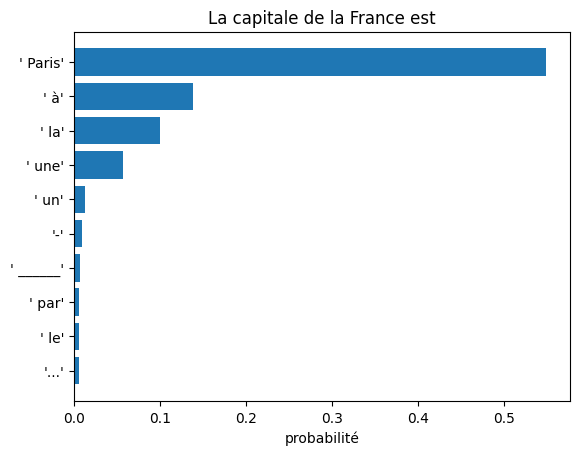

In [10]:
def next_token_distribution(text, temperature=1.0):
    """Renvoie le vecteur des probabilités du token suivant `text`."""
    input_ids = tokenizer(text, return_tensors="pt")["input_ids"].to(model.device)
    with torch.no_grad():  # inférence seule : pas de gradients à mémoriser
        logits = model(input_ids=input_ids).logits[0, -1]  # dernière position = prédiction du token suivant
    return torch.softmax(logits.float() / temperature, dim=-1)


def plot_top_tokens(probs, k=10, title=""):
    """Affiche les k tokens les plus probables sous forme de diagramme en barres."""
    top = torch.topk(probs, k)
    labels = [repr(tokenizer.decode(i)) for i in top.indices]
    plt.barh(labels[::-1], top.values.cpu().numpy()[::-1])
    plt.xlabel("probabilité")
    plt.title(title)
    plt.show()


text = "La capitale de la France est"
probs = next_token_distribution(text)
print(f"Somme des probabilités : {probs.sum().item():.4f}")
plot_top_tokens(probs, title=text)

**Exercice 4** : générer du texte, c'est appeler le modèle en boucle. Écrire la fonction `greedy_decode` qui, à chaque étape, choisit le token le plus probable (*greedy decoding*), l'ajoute à la séquence et recommence, jusqu'à `max_new_tokens` ou jusqu'au token de fin. Comparer avec le résultat de `model.generate(..., do_sample=False)`.

<details>
<summary>💡 Indice 1 : l'algorithme</summary>

```
encoder le texte -> input_ids, de forme (1, L)
mémoriser la longueur du prompt
répéter max_new_tokens fois :
    calculer les logits de la dernière position (comme à l'exercice 3)
    next_id <- indice du logit maximal
    ajouter next_id à la fin de input_ids
    si next_id est un token de fin : sortir de la boucle
décoder uniquement les tokens ajoutés
```
Le softmax est inutile ici : il ne change pas l'ordre des scores, donc le token de plus grand logit est aussi le plus probable.

</details>

<details>
<summary>💡 Indice 2 : les fonctions PyTorch utiles</summary>

- `logits.argmax()` : indice du maximum (tenseur à 0 dimension).
- `torch.cat([a, b], dim=1)` : concatène deux tenseurs selon la dimension des positions. `b` doit avoir la même forme que `a` sauf sur cette dimension, soit `(1, 1)` : `next_id.view(1, 1)`.
- `next_id.item()` convertit le tenseur en entier Python, pour tester `in EOS_IDS`.
- `input_ids[0, prompt_length:]` : les tokens générés seulement ; `tokenizer.decode(..., skip_special_tokens=True)` retire `<|im_end|>`.

</details>

In [11]:
EOS_IDS = model.generation_config.eos_token_id  # liste des ids qui terminent la génération


def greedy_decode(text, max_new_tokens=30):
    """Décodage glouton : ajoute à chaque étape le token de plus grand logit."""
    input_ids = tokenizer(text, return_tensors="pt")["input_ids"].to(model.device)
    prompt_length = input_ids.shape[1]
    with torch.no_grad():
        for _ in range(max_new_tokens):
            # pas de softmax : il ne change pas l'ordre des scores
            next_id = model(input_ids=input_ids).logits[0, -1].argmax()
            input_ids = torch.cat([input_ids, next_id.view(1, 1)], dim=1)
            if next_id.item() in EOS_IDS:
                break
    return tokenizer.decode(input_ids[0, prompt_length:], skip_special_tokens=True)


start = time.perf_counter()
print("Notre boucle    :", repr(greedy_decode(prompt_text)), f"({time.perf_counter() - start:.1f} s)")

inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)
start = time.perf_counter()
output_ids = model.generate(**inputs, max_new_tokens=30, do_sample=False)
reference = tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print("model.generate  :", repr(reference), f"({time.perf_counter() - start:.1f} s)")

Notre boucle    : 'La capitale de la France est Paris.' (1.0 s)
model.generate  : 'La capitale de la France est Paris.' (1.1 s)


**Question** : les deux sorties sont (normalement) identiques, mais `model.generate` est plus rapide. Notre boucle recalcule tout depuis le début à chaque token : quelle optimisation `generate` met-elle en place ? (indice : *KV cache*)

✍️ **Votre réponse :**

Les deux sorties sont identiques : `'La capitale de la France est Paris.'`. Sur cet exemple, les temps mesurés sont très proches (1,0 s pour notre boucle, 1,1 s pour `generate`) : la réponse ne fait que 8 tokens et le prompt est court, donc le surcoût de notre boucle reste négligeable.

Notre boucle **recalcule tout depuis le début à chaque token** : à l'étape *t*, le modèle retraite les *L + t* tokens de la séquence, alors que seuls les logits de la dernière position nous intéressent. Le coût total croît donc avec le carré de la longueur.

`model.generate` utilise un **KV cache** : dans chaque couche d'attention, les clés (*K*) et valeurs (*V*) des tokens déjà traités sont mémorisées. À chaque nouvelle étape, on ne calcule que la représentation du **nouveau** token, qui fait attention aux *K/V* mis en cache. Chaque étape a alors un coût presque constant au lieu de croître avec la séquence ; le gain devient important pour les longues générations (par exemple les 1 369 tokens du mode raisonnement de la partie 4.3). En contrepartie, le cache occupe de la mémoire GPU, proportionnellement au nombre de tokens.

**Exercice 5** : visualiser la distribution du token suivant pour des températures de 0.2, 1.0 et 2.0. Comment la température modifie-t-elle la distribution ? Quelle valeur choisir pour une tâche factuelle ? Pour de l'écriture créative ?

<details>
<summary>💡 Indice</summary>

Une simple boucle sur les températures suffit : réutilisez `next_token_distribution(text, temperature)` et `plot_top_tokens(...)`, en indiquant la température dans le titre. Pour l'analyse, comparez la probabilité du token le plus probable d'un graphique à l'autre.

</details>

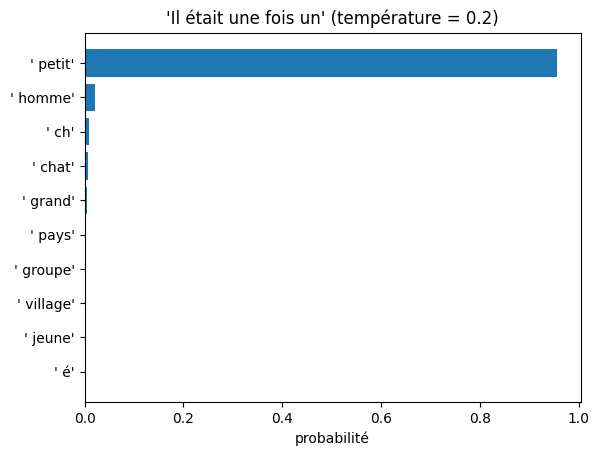

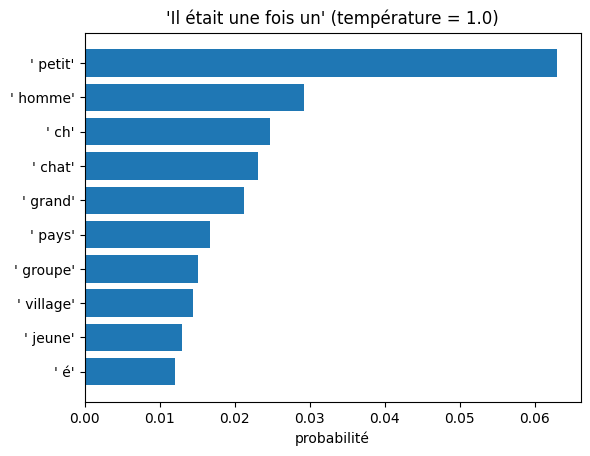

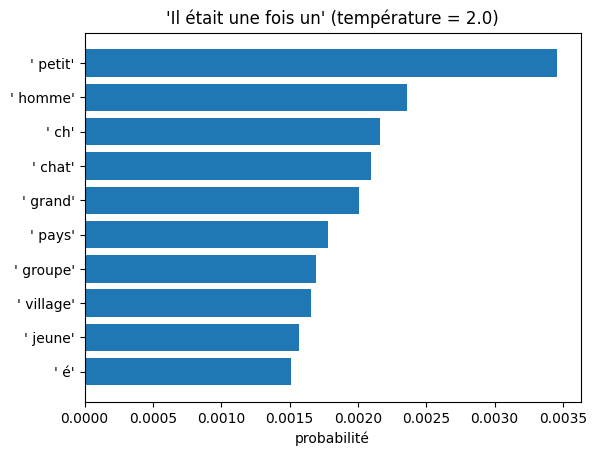

In [12]:
text = "Il était une fois un"

for temperature in (0.2, 1.0, 2.0):
    plot_top_tokens(next_token_distribution(text, temperature), title=f"{text!r} (température = {temperature})")

✍️ **Votre réponse :**

Probabilité du token le plus probable (« petit ») selon la température :
| température | P(« petit ») |
|---|---|
| 0.2 | ≈ 0,95 |
| 1.0 | ≈ 0,06 |
| 2.0 | ≈ 0,0035 |

La température divise les logits avant le softmax : `softmax(z / T)`.
- **T < 1 accentue la distribution** : les écarts entre logits sont amplifiés, le token le plus probable écrase les autres (à T = 0,2, « petit » a 95 % de probabilité) ; on se rapproche du greedy (T → 0).
- **T > 1 aplatit la distribution** : à T = 2, les dix premiers tokens ont tous une probabilité du même ordre (0,15 % à 0,35 %) et les tokens de la « longue traîne » deviennent tirables.

C'est la diapo « Principaux paramètres à l'inférence » du cours : la température aplatit (> 1 : plus créatif) ou accentue (< 1 : plus déterministe) la distribution ; 0 ≈ greedy.
- **Tâche factuelle** : température basse (0 à 0,3) ou décodage greedy, pour une réponse stable et la plus probable.
- **Écriture créative** : température autour de 0,7 à 1,0, combinée avec top-p / top-k pour garder de la diversité sans tirer de tokens absurdes.

## 3. Modèle *base* vs modèle *instruct*

Un LLM est construit en deux grandes étapes :
1. le **pré-entraînement** sur des milliers de milliards de tokens de texte brut : on obtient un modèle **base** qui sait compléter du texte ;
2. le **post-entraînement** (*instruction tuning*, puis apprentissage par renforcement) sur des conversations : on obtient un modèle **instruct** (ou *chat*) qui suit des consignes.

Comparons les deux versions de Qwen3-1.7B sur la même question.

In [13]:
base_model = AutoModelForCausalLM.from_pretrained(f"{MODEL_NAME}-Base", dtype=DTYPE, device_map="auto")

question = "Quelle est la capitale de la France ?"

inputs = tokenizer(question, return_tensors="pt").to(base_model.device)
output_ids = base_model.generate(**inputs, max_new_tokens=60, do_sample=False)
print("BASE, texte brut :\n", tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

chat_text = tokenizer.apply_chat_template(
    [{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True, enable_thinking=False
)
inputs = tokenizer(chat_text, return_tensors="pt").to(model.device)
output_ids = model.generate(**inputs, max_new_tokens=60, do_sample=False)
print("\nINSTRUCT, chat template :\n", tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

# Libérons la mémoire GPU : nous n'utiliserons plus le modèle base.
del base_model
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

BASE, texte brut :
  Quel est le pays le plus peuplé du monde ? Quel est le pays le plus peuplé de l'Europe ? Quel est le pays le plus peuplé du monde ? Quel est le pays le plus peuplé de l'Europe ? Quel est le

INSTRUCT, chat template :
 La capitale de la France est **Paris**.


**Question** : décrivez le comportement du modèle base. Pourquoi « continue »-t-il le texte au lieu de répondre ?

✍️ **Votre réponse :**

Le modèle **base** ne répond pas à la question : il la **continue** par une liste de questions du même genre (« Quel est le pays le plus peuplé du monde ? Quel est le pays le plus peuplé de l'Europe ? ... »), qui se répète jusqu'à la limite de 60 tokens. Le modèle **instruct**, lui, répond « La capitale de la France est **Paris**. »

Explication (diapo « Du modèle pré-entraîné à l'assistant ») : le modèle base n'a subi que le **pré-entraînement**, c'est-à-dire prédire le token suivant sur des milliers de milliards de tokens de texte brut. Il produit donc la suite **la plus vraisemblable** du texte ; or sur le web, une question isolée est souvent suivie d'autres questions (quiz, FAQ, listes d'exercices). Il n'a jamais appris le format « question → réponse » : c'est l'**instruction tuning** (SFT sur des paires instruction/réponse) puis l'**alignement** (RLHF, DPO) qui transforment ce modèle en assistant qui suit des consignes. On l'utilise de plus avec son chat template, qui délimite les rôles.

## 4. Prompt engineering

### Une fonction de génération réutilisable

Pour ne pas répéter le même code à chaque cellule, écrivons une fonction de génération.

**Exercice 6** : compléter la fonction `generate` qui :
- applique le chat template à la liste de `messages` (avec `add_generation_prompt=True`, `enable_thinking=enable_thinking`, `return_tensors="pt"` et `return_dict=True`) et place le résultat sur le device du modèle ;
- appelle `model.generate` en lui transmettant `max_new_tokens` et les paramètres supplémentaires `**gen_kwargs` ;
- renvoie uniquement le texte **généré** (sans le prompt), sans tokens spéciaux et sans espaces superflus.

<details>
<summary>💡 Indice 1 : un exemple déjà présent</summary>

La cellule de l'exercice 4 qui appelle `model.generate` fait presque tout ce qui est demandé : relisez comment elle appelle `generate` et comment elle ne garde que les tokens générés.

</details>

<details>
<summary>💡 Indice 2 : ce que renvoient les fonctions</summary>

- Avec `return_dict=True` et `return_tensors="pt"`, `apply_chat_template` renvoie un dictionnaire (`input_ids`, `attention_mask`) de tenseurs. On le déplace sur le GPU avec `.to(model.device)` et on le passe tel quel à `model.generate(**inputs, ...)`.
- `model.generate` renvoie **le prompt suivi de la réponse** : un tenseur de forme `(1, longueur_prompt + longueur_générée)`. La longueur du prompt est `inputs["input_ids"].shape[1]`.
- `**gen_kwargs` se transmet tel quel : `model.generate(..., **gen_kwargs)`.
- `.strip()` retire les espaces et sauts de ligne au début et à la fin.

</details>

In [14]:
def generate(messages, max_new_tokens=256, enable_thinking=False, **gen_kwargs):
    """Génère la réponse de l'assistant à une liste de messages au format chat."""
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)
    output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, **gen_kwargs)
    # generate renvoie le prompt suivi de la réponse : on ne décode que les tokens générés
    return tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


# Vérification
answer = generate([{"role": "user", "content": "Quelle est la capitale de l'Italie ? Réponds en un mot."}], do_sample=False)
print(answer)
assert answer, "La réponse est vide."
assert "Réponds en un mot" not in answer, "La réponse contient le prompt : ne décodez que les tokens générés."
assert "<|im_end|>" not in answer, "La réponse contient des tokens spéciaux."

Rome.


### Résumé de dialogues

Nous allons utiliser le LLM pour résumer des dialogues du dataset [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum), qui fournit pour chaque dialogue un résumé écrit par un humain.

In [15]:
dataset = load_dataset("knkarthick/dialogsum")
dataset

README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})

In [16]:
example_indices = [40, 200]
dash_line = "-" * 100

for index in example_indices:
    example = dataset["test"][index]
    print(dash_line)
    print(f"DIALOGUE {index} :\n{example['dialogue']}")
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{example['summary']}\n")

----------------------------------------------------------------------------------------------------
DIALOGUE 40 :
#Person1#: What time is it, Tom?
#Person2#: Just a minute. It's ten to nine by my watch.
#Person1#: Is it? I had no idea it was so late. I must be off now.
#Person2#: What's the hurry?
#Person1#: I must catch the nine-thirty train.
#Person2#: You've plenty of time yet. The railway station is very close. It won't take more than twenty minutes to get there.
----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# is in a hurry to catch a train. Tom tells #Person1# there is plenty of time.

----------------------------------------------------------------------------------------------------
DIALOGUE 200 :
#Person1#: Have you considered upgrading your system?
#Person2#: Yes, but I'm not sure what exactly I would need.
#Person1#: You could consider adding a painting program to your software. It would allow you

Tentons une première approche : envoyer le dialogue seul, sans aucune consigne.

In [17]:
for index in example_indices:
    dialogue = dataset["test"][index]["dialogue"]
    output = generate([{"role": "user", "content": dialogue}], max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][index]['summary']}")
    print(f"\nSORTIE DU LLM SANS CONSIGNE :\n{output}\n")

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# is in a hurry to catch a train. Tom tells #Person1# there is plenty of time.

SORTIE DU LLM SANS CONSIGNE :
Let's break down the timeline based on the conversation:

---

### **Person2** says:  
> "It's ten to nine by my watch."

This means **9:50 PM** is the current time.

---

### **Person1** says:  
> "I must catch the nine-thirty train."

A **nine-thirty train** is **9:30 PM**.

---

### **Person2** says:  
> "You've plenty of time yet. The

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.

SORTIE DU LLM SANS CONSIGNE :
That conversation is a great example of how people can discuss upgrading their systems in a natural, conversational way. Here's a summary and a more structured version of the interaction:

**Question** : est-ce un bon résumé ? Pourquoi ?

✍️ **Votre réponse :**

Non, ce ne sont pas de bons résumés.
- **Pas de résumé** : sans consigne, le modèle ne sait pas quelle tâche on attend. Il reformule le dialogue réplique par réplique en Markdown (« Let's break down the timeline... », « Here's a summary and a more structured version... ») au lieu de le condenser en une ou deux phrases.
- **Erreur factuelle** : pour le dialogue 40, il affirme que « ten to nine » signifie **9:50 PM**, alors que cela signifie 8 h 50. C'est une **hallucination** : une réponse fausse mais plausible.
- **Réponse tronquée** : le texte est coupé par `max_new_tokens=100` avant d'avoir conclu.
- **Format différent** des références (qui désignent les personnes par `#Person1#`).

Le prompt ne contenait que le dialogue : il manquait la **tâche** et le **format** attendus (canevas du cours : persona, tâche, contexte, format).

### 4.1 Zero-shot

Ajoutons une consigne dans un **system prompt**, qui définit le rôle et le comportement de l'assistant pour toute la conversation. Fournir seulement une consigne, sans exemple, s'appelle l'inférence **zero-shot**.

In [18]:
SYSTEM_PROMPT = (
    "You summarize dialogues. Write a short summary (one or two sentences) in English, "
    "in the third person, focusing on the key points."
)

for index in example_indices:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": dataset["test"][index]["dialogue"]},
    ]
    output = generate(messages, max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][index]['summary']}")
    print(f"\nRÉSUMÉ ZERO-SHOT :\n{output}\n")

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# is in a hurry to catch a train. Tom tells #Person1# there is plenty of time.

RÉSUMÉ ZERO-SHOT :
Tom asks what time it is, and Person2 replies that it's ten to nine. Tom is surprised and says he must catch the nine-thirty train, but Person2 insists he has plenty of time and the station is close.

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.

RÉSUMÉ ZERO-SHOT :
Person2 considers upgrading their system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software requirements.



C'est bien mieux ! Mais le style ne correspond pas encore à celui des résumés humains (qui désignent par exemple les personnes par `#Person1#`). Montrons des exemples au modèle.

### 4.2 One-shot et few-shot

L'inférence **one-shot** et **few-shot** consiste à fournir au modèle un ou plusieurs exemples complets (dialogue, résumé) avant le dialogue à traiter. C'est l'**apprentissage en contexte** (*in-context learning*) : le modèle s'adapte à la tâche sans modifier ses poids.

Avec un modèle conversationnel, chaque exemple est représenté par un **tour de conversation** : un message `user` (le dialogue) suivi d'un message `assistant` (le résumé attendu).

Les exemples sont tirés du split `train` et l'évaluation se fait sur le split `test` : on ne doit jamais montrer au modèle les données sur lesquelles on l'évalue.

**Exercice 7** : compléter la fonction `make_messages` qui construit la liste de messages : le system prompt, puis un couple (`user`, `assistant`) par exemple de `shots`, puis le dialogue à résumer.

<details>
<summary>💡 Indice 1 : la liste attendue</summary>

Avec 2 exemples, la fonction doit renvoyer :
```python
[
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": "<dialogue de l'exemple 1>"},
    {"role": "assistant", "content": "<résumé de l'exemple 1>"},
    {"role": "user", "content": "<dialogue de l'exemple 2>"},
    {"role": "assistant", "content": "<résumé de l'exemple 2>"},
    {"role": "user", "content": dialogue},
]
```

</details>

<details>
<summary>💡 Indice 2 : parcourir les exemples</summary>

`shots` est une liste ou un `Dataset` Hugging Face : dans les deux cas, `for shot in shots:` donne un dictionnaire par exemple, et le texte s'obtient avec `shot["dialogue"]` et `shot["summary"]`. Vérifiez le résultat avec le chat template affiché sous la cellule : l'exemple doit apparaître avant le dialogue à résumer.

</details>

In [19]:
def make_messages(dialogue, shots=(), system_prompt=SYSTEM_PROMPT):
    """Construit un prompt few-shot. `shots` est une liste d'exemples {"dialogue": ..., "summary": ...}."""
    messages = [{"role": "system", "content": system_prompt}]
    for shot in shots:  # un tour de conversation (user, assistant) par exemple
        messages += [
            {"role": "user", "content": shot["dialogue"]},
            {"role": "assistant", "content": shot["summary"]},
        ]
    messages.append({"role": "user", "content": dialogue})
    return messages


one_shot = dataset["train"].select([0])
messages = make_messages(dataset["test"][200]["dialogue"], one_shot)
print(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False))

<|im_start|>system
You summarize dialogues. Write a short summary (one or two sentences) in English, in the third person, focusing on the key points.<|im_end|>
<|im_start|>user
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some

In [20]:
few_shot = dataset["train"].select([0, 1, 2])

for name, shots in {"ONE-SHOT": one_shot, "FEW-SHOT (3 exemples)": few_shot}.items():
    output = generate(make_messages(dataset["test"][200]["dialogue"], shots), max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"{name} :\n{output}")
print(dash_line)
print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][200]['summary']}")

----------------------------------------------------------------------------------------------------
ONE-SHOT :
Person1 suggests upgrading the system, recommends adding a painting program and hardware upgrades like a faster processor, more memory, and a CD-ROM drive, and Person2 agrees, noting the benefits of the upgrades.
----------------------------------------------------------------------------------------------------
FEW-SHOT (3 exemples) :
Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.


**Question** : combien de tokens compte le prompt few-shot ? Les anciennes versions de ce TP utilisaient `flan-t5` (fenêtre de 512 tokens) avec 3 exemples : que se passait-il ?

<details>
<summary>💡 Indice</summary>

Sans `tokenize=False`, `apply_chat_template` renvoie des ids : avec `return_dict=True`, ils sont sous la clé `"input_ids"`. Il reste à en prendre la longueur (pensez aussi à `add_generation_prompt=True` et `enable_thinking=False`, comme dans `generate`).

</details>

In [21]:
def count_prompt_tokens(messages):
    """Nombre de tokens du prompt tel qu'il est envoyé au modèle (chat template appliqué)."""
    return len(
        tokenizer.apply_chat_template(messages, add_generation_prompt=True, enable_thinking=False, return_dict=True)[
            "input_ids"
        ]
    )


dialogue = dataset["test"][200]["dialogue"]
for name, shots in {"zero-shot": [], "one-shot": one_shot, "few-shot (3 exemples)": few_shot}.items():
    print(f"{name:22s}: {count_prompt_tokens(make_messages(dialogue, shots))} tokens")

zero-shot             : 229 tokens
one-shot              : 523 tokens
few-shot (3 exemples) : 942 tokens


✍️ **Votre réponse :**

Le prompt few-shot (3 exemples + le dialogue 200) compte **942 tokens**, contre 229 en zero-shot et 523 en one-shot : chaque exemple coûte environ 300 tokens.

Avec `flan-t5`, la fenêtre de contexte est de **512 tokens** : un prompt de 3 exemples ne tenait pas. Le texte était **tronqué**, et la partie coupée pouvait être le dialogue à résumer lui-même. Le modèle résumait alors un prompt incomplet : les mauvais résultats du few-shot ne venaient pas de la technique elle-même mais de la troncature. Les conclusions des anciennes versions du TP sur le few-shot étaient donc faussées. Avec Qwen3 (131 072 tokens de contexte), le problème ne se pose plus pour quelques exemples.

**Exercice 8** : modifier les exemples fournis (nombre, choix, exemples très différents du dialogue à résumer...) et le system prompt. Notez vos observations dans une cellule markdown. Les comparaisons à l'œil ont leurs limites : nous mesurerons objectivement l'apport du few-shot dans la partie 6.

<details>
<summary>💡 Pistes d'expériences</summary>

- 0, 1, 3 puis 5 exemples : le gain continue-t-il ? Combien de tokens coûte chaque exemple ?
- des exemples très différents du dialogue à résumer, ou au contraire proches ;
- un system prompt plus précis (« désigne les personnes par #Person1# et #Person2# »), ou en français ;
- un exemple au résumé volontairement mauvais : le modèle l'imite-t-il ?

</details>

In [22]:
dialogue = dataset["test"][200]["dialogue"]
print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][200]['summary']}\n")

# 1. Nombre d'exemples : 0, 1, 3 puis 5
for n_shots in (0, 1, 3, 5):
    messages = make_messages(dialogue, dataset["train"].select(range(n_shots)))
    print(dash_line)
    print(f"{n_shots} exemple(s), {count_prompt_tokens(messages)} tokens :")
    print(generate(messages, max_new_tokens=100, do_sample=False))

# 2. Variantes du system prompt et des exemples
variants = {
    "system prompt précis (#Person1#), zero-shot": make_messages(
        dialogue, [], SYSTEM_PROMPT + " Refer to the speakers as #Person1# and #Person2#."
    ),
    "system prompt en français, zero-shot": make_messages(
        dialogue, [], "Tu résumes des dialogues en une ou deux phrases, en français, à la troisième personne."
    ),
    "exemple au résumé volontairement mauvais": make_messages(
        dialogue, [{"dialogue": dataset["train"][0]["dialogue"], "summary": "They talk."}]
    ),
}
for name, messages in variants.items():
    print(dash_line)
    print(f"{name} :")
    print(generate(messages, max_new_tokens=100, do_sample=False))

RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.

----------------------------------------------------------------------------------------------------
0 exemple(s), 229 tokens :
Person2 considers upgrading their system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software requirements.
----------------------------------------------------------------------------------------------------
1 exemple(s), 523 tokens :
Person1 suggests upgrading the system, recommends adding a painting program and hardware upgrades like a faster processor, more memory, and a CD-ROM drive, and Person2 agrees, noting the benefits of the upgrades.
----------------------------------------------------------------------------------------------------
3 exemple(s), 942 tokens :
Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software

✍️ **Votre réponse :**

Observations sur le dialogue 200 (résumé humain : « #Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system. »), en greedy :

**Nombre d'exemples**
| exemples | tokens du prompt | résumé |
|---|---|---|
| 0 | 229 | centré sur Person2 (« Person2 considers upgrading... ») |
| 1 | 523 | plus long, avec les détails matériels (processeur, mémoire) |
| 3 | 942 | « Person1 suggests upgrading the system by adding a painting program and improving hardware... » |
| 5 | 1 303 | **identique** au résumé à 3 exemples |

Le gain ne continue pas au-delà de 3 exemples, alors que chaque exemple coûte environ 300 tokens supplémentaires (coût, vitesse, fenêtre de contexte).

**Variantes**
- **System prompt précis** (« Refer to the speakers as #Person1# and #Person2# ») : le modèle adopte immédiatement le style des références (`#Person1# suggests...`). Une consigne précise suffit ici à obtenir le format, sans exemple.
- **System prompt en français** : échec. Le modèle **traduit le dialogue en français** réplique par réplique au lieu de le résumer : avec un petit modèle, une consigne différente de la langue du contenu peut être mal interprétée.
- **Exemple au résumé volontairement mauvais** (« They talk. ») : le modèle reprend la formulation vague de l'exemple (« They discuss upgrading the system... ») tout en restant informatif. Les exemples influencent bien le style de la sortie : leur qualité compte.

Ces comparaisons portent sur un seul dialogue : la partie 6 mesure l'effet sur 20 dialogues.

### 4.3 Modèles de raisonnement (*thinking*)

Depuis fin 2024 (OpenAI o1, DeepSeek-R1...), les modèles de **raisonnement** produisent une longue réflexion avant de répondre : ils dépensent plus de calcul au moment de l'inférence (*test-time compute*) pour améliorer leurs réponses. Qwen3 est un modèle hybride : le paramètre `enable_thinking` du chat template active ou désactive ce mode. La réflexion est délimitée par les balises `<think>` et `</think>`.

Qwen recommande des paramètres d'échantillonnage différents selon le mode : nous les utilisons ci-dessous.

In [23]:
puzzle = [{
    "role": "user",
    "content": "Alice a 3 frères. Chacun de ses frères a 2 sœurs. Combien de sœurs Alice a-t-elle ?",
}]

for enable_thinking in [False, True]:
    sampling = (
        dict(temperature=0.6, top_p=0.95, top_k=20) if enable_thinking else dict(temperature=0.7, top_p=0.8, top_k=20)
    )
    set_seed(0)
    start = time.perf_counter()
    output = generate(puzzle, max_new_tokens=2048, enable_thinking=enable_thinking, do_sample=True, **sampling)
    elapsed = time.perf_counter() - start

    print(dash_line)
    print(f"enable_thinking={enable_thinking} : {len(tokenizer(output)['input_ids'])} tokens générés en {elapsed:.1f} s")
    if enable_thinking and "</think>" not in output:
        print("\nRéflexion non terminée : max_new_tokens atteint.")
        continue
    thinking, _, answer = output.rpartition("</think>")
    if thinking:
        print(f"\nRÉFLEXION (début) :\n{thinking.replace('<think>', '').strip()[:800]}...")
    print(f"\nRÉPONSE :\n{answer.strip()}")

----------------------------------------------------------------------------------------------------
enable_thinking=False : 357 tokens générés en 15.5 s

RÉPONSE :
Pour résoudre ce problème, commençons par comprendre les informations données :

- **Alice a 3 frères**.
- **Chacun de ses frères a 2 sœurs**.

### 1. Analysons les données :

- Alice a **3 frères**. Cela signifie qu'il y a **3 hommes** qui sont ses frères.
- Chacun de ces 3 frères a **2 sœurs**. Cela signifie que chaque frère a **2 sœurs**.

### 2. Quelle est la quantité de sœurs que **Alice a** ?

Nous devons déterminer **combien de sœurs Alice a**.

Nous savons que **chaque frère a 2 sœurs**, et il y a **3 frères**.

Mais attention : **Alice n'est pas un frère**, donc elle **n'a pas de sœurs** parmi les frères de la famille.

Mais nous devons déterminer **combien de sœurs Alice a** en tenant compte de la quantité de sœurs que les frères ont.

### 3. Calculons :

- Chaque frère a **2 sœurs**.
- Il y a **3 frères**.
- Cela

**Question** : comparez les réponses, le nombre de tokens générés et le temps de calcul. Relancez plusieurs fois (changez la graine) : les réponses sont-elles stables ? Dans quels cas le mode raisonnement vaut-il son coût ?

✍️ **Votre réponse :**

Résultats (graine 0, échantillonnage recommandé par Qwen pour chaque mode) :
| mode | tokens générés | temps |
|---|---|---|
| sans raisonnement | 357 | 15,5 s |
| avec raisonnement | 1 369 | 59,6 s |

**Les deux réponses sont fausses** : le modèle répond « 2 sœurs », alors que la bonne réponse est **1**. Chaque frère a 2 sœurs : Alice et une autre fille. Le mode raisonnement a coûté près de 4 fois plus de tokens et de temps sans corriger l'erreur. Dans sa réponse, il écrit même que les sœurs de chaque frère « incluent Alice et une autre fille », ce qui donne 1 sœur pour Alice, puis conclut quand même « 2 ». Un modèle de 1,7 milliard de paramètres reste limité sur ce type d'énigme.

**Stabilité** : ce notebook n'a été exécuté qu'avec la graine 0. Comme la génération est échantillonnée (`do_sample=True`), la réponse peut changer d'une graine à l'autre : il faudrait relancer avec plusieurs graines (`set_seed(1)`, `set_seed(2)`...) et compter la proportion de bonnes réponses pour juger la stabilité.

**Quand le raisonnement vaut-il son coût ?** Le cours parle de *test-time compute* : plus de calcul à l'inférence donne de meilleurs résultats en maths, code et planification, mais c'est plus lent et plus cher. Il est utile pour les tâches à plusieurs étapes où une erreur coûte cher, à condition de vérifier qu'il améliore réellement l'exactitude sur un jeu de test (dans le mini-projet, il a amélioré l'extraction). Pour une question factuelle simple, une reformulation ou un résumé, il fait perdre du temps et des tokens.

## 5. Influence des paramètres de génération

Au lieu de toujours choisir le token le plus probable (*greedy*), on peut **échantillonner** le token suivant dans la distribution calculée par le modèle. Plusieurs paramètres contrôlent cet échantillonnage :
- `do_sample` : active l'échantillonnage (sinon : greedy) ;
- `temperature` : aplatit ou accentue la distribution (vu à l'exercice 5) ;
- `top_k` : ne garde que les k tokens les plus probables ;
- `top_p` : ne garde que les tokens les plus probables dont la probabilité cumulée atteint p (*nucleus sampling*, p entre 0 et 1).

Documentation : [stratégies de génération](https://huggingface.co/docs/transformers/generation_strategies) et [GenerationConfig](https://huggingface.co/docs/transformers/main_classes/text_generation).

Notez que le modèle a ses propres valeurs par défaut, définies par ses auteurs :

In [24]:
model.generation_config

GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}

**Exercice 9** : écrire une fonction `generate_summary(dialogue, temperature, top_k, top_p, do_sample, shots=few_shot)` qui renvoie le résumé généré avec ces paramètres (réutilisez `make_messages` et `generate`). Puis générer **3 résumés** du dialogue 200 pour chaque configuration de `configs`.

<details>
<summary>💡 Indice 1 : la fonction</summary>

Le corps de `generate_summary` se résume à un appel à `generate` : les messages viennent de `make_messages(dialogue, shots)`, et `do_sample`, `temperature`, `top_k`, `top_p` sont transmis par l'intermédiaire de `**gen_kwargs`. Utilisez `max_new_tokens=100`, comme dans la partie 4.

</details>

<details>
<summary>💡 Indice 2 : appliquer une configuration</summary>

Chaque élément de `configs` est un dictionnaire dont les clés sont les noms des paramètres : `generate_summary(dialogue, **config)` le « déballe » en arguments nommés. Il reste une double boucle : sur les configurations, puis 3 fois pour chaque configuration.

Les `None` de la configuration greedy évitent un avertissement de `transformers` : sans échantillonnage, la température et le filtrage n'ont pas de sens.

</details>

In [25]:
configs = [
    dict(do_sample=False, temperature=None, top_k=None, top_p=None),  # greedy
    dict(do_sample=True, temperature=0.3, top_k=50, top_p=0.9),
    dict(do_sample=True, temperature=1.0, top_k=50, top_p=0.9),
    dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0),         # aucun filtrage
]


def generate_summary(dialogue, temperature, top_k, top_p, do_sample, shots=few_shot):
    """Résumé few-shot du dialogue avec les paramètres d'échantillonnage donnés."""
    return generate(
        make_messages(dialogue, shots),
        max_new_tokens=100,
        do_sample=do_sample,
        temperature=temperature,
        top_k=top_k,
        top_p=top_p,
    )


set_seed(42)  # rend l'ensemble de la cellule reproductible
dialogue = dataset["test"][200]["dialogue"]
for config in configs:
    print(dash_line)
    print(config)
    for i in range(1, 4):
        print(f"{i}. {generate_summary(dialogue, **config)}")

----------------------------------------------------------------------------------------------------
{'do_sample': False, 'temperature': None, 'top_k': None, 'top_p': None}
1. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
2. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
3. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
----------------------------------------------------------------------------------------------------
{'do_sample': True, 'temperature': 0.3, 'top_k': 50, 'top_p': 0.9}
1. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software. Person2 expresses gratitude and agrees to proceed.
2. Person1 suggests upgradin

**Exercice 10** : expliquer en 1 ou 2 lignes l'influence de chacun des 4 paramètres, en vous appuyant sur vos observations.

<details>
<summary>💡 Questions pour guider l'analyse</summary>

- Les 3 résumés greedy sont-ils identiques ? Et ceux des autres configurations ?
- À partir de quelle configuration le texte devient-il incohérent ? Pourquoi la dernière configuration (`top_k=0`, `top_p=1.0`) est-elle la plus risquée ?
- Revoyez les graphiques de l'exercice 5 : que deviennent les tokens de la « longue traîne » quand on les filtre ?

</details>

✍️ **Votre réponse :**

Observations sur 3 résumés du dialogue 200 par configuration :
- **`do_sample`** : à `False` (greedy), le modèle prend toujours le token le plus probable, et les 3 résumés sont **strictement identiques** (sortie déterministe). À `True`, le token est tiré au hasard selon la distribution, et les résumés varient d'un appel à l'autre.
- **`temperature`** : elle règle l'ampleur de la variation. À 0,3, les résumés sont presque identiques au greedy (un seul ajoute une phrase). À 1,0, la formulation change à chaque fois (« to support new software that comes on CDs », « as most new software is released on CDs »...). À 1,5, la variété augmente encore (« better storage » apparaît).
- **`top_k`** : ne garde que les *k* tokens les plus probables avant le tirage (ici 50). Les tokens de la longue traîne, qui à haute température deviennent tirables (voir l'exercice 5), sont exclus.
- **`top_p`** (*nucleus sampling*) : ne garde que le plus petit ensemble de tokens dont la probabilité cumulée atteint *p* (ici 0,9). La taille de l'ensemble s'adapte à la confiance du modèle : peu de tokens quand il est sûr, davantage quand il hésite.

La dernière configuration (T = 1,5 avec `top_k=0` et `top_p=1.0`, c'est-à-dire aucun filtrage) est la plus risquée : la distribution est aplatie **et** aucun token n'est écarté, si bien qu'un token absurde peut être tiré, et une fois tiré il entraîne la suite du texte. Sur ce dialogue, les 3 résumés sont restés cohérents (les 3 exemples few-shot et la consigne contraignent fortement la sortie, qui ne fait que 100 tokens au plus), mais rien ne le garantit sur d'autres entrées ou des textes plus longs.

## 6. Évaluation automatique avec ROUGE

Jusqu'ici, nous avons jugé les résumés « à l'œil » sur 1 ou 2 exemples : ce n'est pas une évaluation. La métrique **ROUGE** mesure le recouvrement de mots entre un résumé généré et un résumé de référence :
- ROUGE-1 : recouvrement des mots ;
- ROUGE-2 : recouvrement des paires de mots consécutifs ;
- ROUGE-L : plus longue sous-séquence commune.

In [26]:
import evaluate

rouge = evaluate.load("rouge")
rouge.compute(
    predictions=["#Person1# asks #Person2# to send the report today."],
    references=["#Person1# wants #Person2# to send the report by the end of the day."],
)

{'rouge1': np.float64(0.5714285714285714),
 'rouge2': np.float64(0.4210526315789474),
 'rougeL': np.float64(0.5714285714285714),
 'rougeLsum': np.float64(0.5714285714285714)}

Le split `test` de DialogSum fournit **3 résumés humains par dialogue** (identifiants `test_N_1`, `test_N_2`, `test_N_3`, sur 3 lignes consécutives). ROUGE accepte plusieurs références par prédiction : le score est calculé par rapport à la référence la plus proche.

**Exercice 11** : comparer les approches zero-shot, one-shot et few-shot sur 20 dialogues distincts du split `test` (en greedy, pour la reproductibilité). Construire un DataFrame avec une ligne par approche et une colonne par score ROUGE, puis l'afficher sous forme de diagramme en barres. Conservez les résumés few-shot dans une variable `few_shot_summaries` : ils serviront dans la partie 8.

Optimisation (bonus) : la génération un par un est lente. Comment générer plusieurs résumés en une seule passe ? (indice : *batching*, `padding_side="left"`)

<details>
<summary>💡 Indice 1 : organiser le code</summary>

- Le zero-shot est un few-shot avec une liste d'exemples vide : `make_messages(dialogue, [])`. Un dictionnaire `{nom_approche: exemples}` permet de traiter les trois approches avec la même boucle.
- `eval_set["dialogue"]` est la liste des 20 dialogues.
- 3 approches × 20 dialogues = 60 générations, soit plusieurs minutes : testez d'abord votre code sur 2 dialogues.

</details>

<details>
<summary>💡 Indice 2 : scores et graphique</summary>

- `rouge.compute(predictions=liste_de_20_résumés, references=eval_references)` renvoie un dictionnaire `{"rouge1": ..., "rouge2": ..., ...}`.
- `pd.DataFrame({nom: dictionnaire_de_scores, ...})` crée une **colonne** par approche ; `.T` (transposée) donne une ligne par approche.
- `df.plot.bar()` trace directement le diagramme.

</details>

<details>
<summary>💡 Indice 3 (bonus) : le batching</summary>

On passe plusieurs conversations à la fois au modèle. Elles n'ont pas la même longueur : il faut compléter les plus courtes avec des tokens de remplissage (*padding*), à **gauche** (`tokenizer.padding_side = "left"`). Les tokens générés s'ajoutent à droite : un remplissage à droite s'intercalerait entre le prompt et la réponse.

</details>

60 résumés générés en 24 s


,rouge1,rouge2,rougeL,rougeLsum
zero-shot,0.352,0.131,0.285,0.285
one-shot,0.328,0.116,0.264,0.265
few-shot,0.368,0.146,0.306,0.307


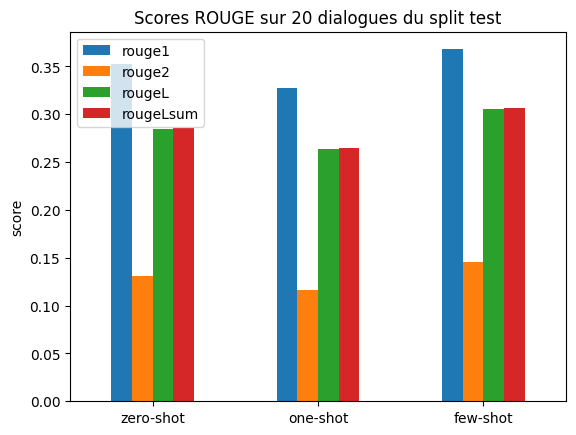

In [27]:
eval_set = dataset["test"].select(range(0, 60, 3))  # 20 dialogues distincts
eval_references = [dataset["test"][i:i + 3]["summary"] for i in range(0, 60, 3)]  # 3 références par dialogue

# Optimisation : génération par lots (batching). Les prompts n'ont pas la même longueur : on les complète
# par des tokens de remplissage à GAUCHE, pour que les tokens générés suivent directement chaque prompt.
tokenizer.padding_side = "left"


def generate_batch(conversations, max_new_tokens=100, batch_size=10, **gen_kwargs):
    """Génère les réponses à plusieurs conversations, `batch_size` conversations par passage dans le modèle."""
    outputs = []
    for start in range(0, len(conversations), batch_size):
        inputs = tokenizer.apply_chat_template(
            conversations[start:start + batch_size],
            add_generation_prompt=True,
            enable_thinking=False,
            padding=True,
            return_tensors="pt",
            return_dict=True,
        ).to(model.device)
        output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, **gen_kwargs)
        generated = tokenizer.batch_decode(output_ids[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        outputs += [text.strip() for text in generated]
    return outputs


approaches = {"zero-shot": [], "one-shot": one_shot, "few-shot": few_shot}  # le zero-shot = aucun exemple

start = time.perf_counter()
summaries = {
    name: generate_batch([make_messages(dialogue, shots) for dialogue in eval_set["dialogue"]], do_sample=False)
    for name, shots in approaches.items()
}
print(f"{3 * len(eval_set)} résumés générés en {time.perf_counter() - start:.0f} s")
few_shot_summaries = summaries["few-shot"]  # réutilisés dans la partie 8

rouge_scores = pd.DataFrame(
    {name: rouge.compute(predictions=predictions, references=eval_references) for name, predictions in summaries.items()}
).T
display(rouge_scores.round(3))
rouge_scores.plot.bar(title="Scores ROUGE sur 20 dialogues du split test", ylabel="score", rot=0)
plt.show()

**Question** : quelle approche obtient les meilleurs scores ? Citez au moins deux limites de ROUGE.

✍️ **Votre réponse :**

Scores ROUGE sur 20 dialogues du split `test` (greedy, 3 références par dialogue) :
| approche | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---|---|---|
| zero-shot | 0,352 | 0,131 | 0,285 |
| one-shot | 0,328 | 0,116 | 0,264 |
| **few-shot** | **0,368** | **0,146** | **0,306** |

Le **few-shot** obtient les meilleurs scores sur les trois métriques. Le **one-shot est légèrement en dessous du zero-shot** : un seul exemple peut orienter le modèle vers le style de cet exemple particulier plutôt que vers celui des résumés en général. Les écarts restent faibles (environ 0,02 en ROUGE-1) sur seulement 20 dialogues : ils ne sont pas forcément significatifs.

Optimisation : les 60 résumés ont été générés **par lots** (*batching*, remplissage à gauche) en 24 s au total.

**Limites de ROUGE**
- **Recouvrement lexical uniquement** : une paraphrase correcte (« teaches » / « suggests », « Person1 » / « #Person1# ») est pénalisée, alors qu'un résumé qui recopie les mots du dialogue est favorisé.
- **Pas de mesure de la fidélité** : un résumé qui contient une information fausse mais réutilise les bons mots peut obtenir un bon score. ROUGE ne détecte pas les hallucinations.
- **Dépendance aux références** : le score dépend du style des résumés humains (comme `#Person1#`) et de leur nombre. Un bon résumé formulé différemment obtient un score faible.
- Sur 20 dialogues, la variance est grande ; il faudrait plus d'exemples pour conclure.

## 7. Sorties structurées

Dans une application, on a rarement besoin de texte libre : on veut des **données exploitables** (pour remplir une base de données, appeler une API...). On demande alors au LLM de répondre en **JSON** respectant un schéma, que l'on valide avec [Pydantic](https://docs.pydantic.dev/).

Définissons le schéma des informations à extraire d'un dialogue.

In [28]:
from typing import Literal

from pydantic import BaseModel, Field, ValidationError


class DialogueInfo(BaseModel):
    topic: str = Field(description="Sujet principal du dialogue, en quelques mots")
    location: str = Field(description="Lieu où se déroule le dialogue, ou \"inconnu\" s'il n'est pas identifiable")
    action_items: list[str] = Field(description="Actions que les participants prévoient de faire")
    sentiment: Literal["positive", "neutral", "negative"] = Field(description="Ton général du dialogue")


def type_name(annotation):
    return annotation.__name__ if isinstance(annotation, type) else str(annotation).replace("typing.", "")


def describe_schema(schema):
    """Décrit les champs d'un modèle Pydantic, une ligne par champ (plus lisible qu'un schéma JSON pour un petit LLM)."""
    return "\n".join(
        f"- {name} ({type_name(field.annotation)}) : {field.description}" for name, field in schema.model_fields.items()
    )


print(describe_schema(DialogueInfo))

- topic (str) : Sujet principal du dialogue, en quelques mots
- location (str) : Lieu où se déroule le dialogue, ou "inconnu" s'il n'est pas identifiable
- action_items (list[str]) : Actions que les participants prévoient de faire
- sentiment (Literal['positive', 'neutral', 'negative']) : Ton général du dialogue


**Exercice 12** : compléter la fonction générique `generate_structured(messages, schema, max_retries=3)` qui :
1. ajoute au dernier message une consigne demandant de répondre uniquement en JSON avec les champs décrits par `describe_schema(schema)` ;
2. génère une réponse et extrait le JSON du texte (le modèle l'entoure parfois de balises Markdown) avec la fonction `extract_json` fournie ;
3. valide le JSON avec `schema.model_validate_json(...)`, qui lève une `ValidationError` en cas de problème ;
4. en cas d'erreur, ajoute la réponse fautive et le message d'erreur à la conversation, et redemande une correction au modèle, au plus `max_retries` fois. Attention : en décodage greedy, le modèle risque de reproduire exactement la même erreur. Pour les nouvelles tentatives, activez l'échantillonnage (`do_sample=True`).

<details>
<summary>💡 Indice 1 : ajouter la consigne sans modifier la liste reçue</summary>

Ne modifiez pas `messages` en place : la liste appartient à l'appelant. Construisez une nouvelle liste : tous les messages sauf le dernier (`messages[:-1]`), puis une copie du dernier message dont le contenu est complété. `{**message, "content": nouveau_contenu}` crée une copie d'un dictionnaire en remplaçant une clé.

</details>

<details>
<summary>💡 Indice 2 : le squelette</summary>

```
messages <- copie avec la consigne JSON ajoutée au dernier message
pour chaque tentative parmi max_retries :
    si ce n'est pas la première tentative :
        activer l'échantillonnage dans gen_kwargs
    raw <- generate(messages, ...)
    try:
        renvoyer schema.model_validate_json(extract_json(raw))
    except ValidationError as error:
        ajouter à messages la réponse fautive (rôle "assistant")
        puis un message "user" contenant l'erreur et demandant une correction
lever une ValueError : aucune tentative n'a abouti
```
Renvoyer la réponse fautive au modèle lui permet de « voir » son erreur dans la conversation. Levez bien une `ValueError` à la fin : l'exercice 13 s'appuie dessus.

</details>

<details>
<summary>💡 Indice 3 : détails Python</summary>

- `model_validate_json` lève une `ValidationError` aussi bien pour un JSON mal formé que pour un champ manquant ou du mauvais type.
- Pour activer l'échantillonnage sans modifier le dictionnaire de l'appelant : `gen_kwargs = {**gen_kwargs, "do_sample": True, "temperature": 0.7}`.
- La variable `error` du bloc `except` est effacée à la sortie de ce bloc : si vous voulez l'afficher dans la `ValueError` finale, conservez-la dans une autre variable.

</details>

In [29]:
def extract_json(text):
    """Extrait le premier objet JSON {...} d'un texte, en ignorant un éventuel bloc de raisonnement <think>...</think>."""
    text = text.rpartition("</think>")[2]
    match = re.search(r"\{.*\}", text, re.DOTALL)
    return match.group(0) if match else text


def generate_structured(messages, schema, max_retries=3, max_new_tokens=512, **gen_kwargs):
    """Génère une réponse validée par le modèle Pydantic `schema`."""
    instruction = (
        "\n\nRéponds uniquement avec un objet JSON contenant exactement les champs suivants :\n"
        f"{describe_schema(schema)}"
    )
    # nouvelle liste : on ne modifie pas les messages de l'appelant
    messages = [*messages[:-1], {**messages[-1], "content": messages[-1]["content"] + instruction}]
    last_error = None
    for attempt in range(max_retries):
        if attempt > 0:  # en greedy, le modèle reproduirait exactement la même erreur
            gen_kwargs = {**gen_kwargs, "do_sample": True, "temperature": 0.7}
        raw = generate(messages, max_new_tokens=max_new_tokens, **gen_kwargs)
        try:
            return schema.model_validate_json(extract_json(raw))
        except ValidationError as error:
            last_error = error  # `error` est effacée à la sortie du bloc except
            messages = [
                *messages,
                {"role": "assistant", "content": raw},
                {
                    "role": "user",
                    "content": f"Ta réponse n'est pas valide :\n{error}\nCorrige-la et réponds uniquement avec le JSON.",
                },
            ]
    raise ValueError(f"Aucune réponse valide après {max_retries} tentatives. Dernière erreur : {last_error}")


info = generate_structured(
    [{"role": "user", "content": f"Extrais les informations de ce dialogue :\n\n{dataset['test'][40]['dialogue']}"}],
    DialogueInfo,
    do_sample=False,
)
info

DialogueInfo(topic='Heure et déplacement vers le train', location='environnement de la gare de train', action_items=["Tom vérifie l'heure", 'Tom prévoit de prendre le train à 9h30', 'Personne ne prévoit de rester plus longtemps'], sentiment='neutral')

Appliquons l'extraction à plusieurs dialogues : nous obtenons directement une table, prête à être insérée dans une base de données.

In [30]:
rows = [
    generate_structured(
        [{"role": "user", "content": f"Extrais les informations de ce dialogue :\n\n{dialogue}"}],
        DialogueInfo,
        do_sample=False,
    ).model_dump()
    for dialogue in eval_set.select(range(5))["dialogue"]
]
pd.DataFrame(rows)

,topic,location,action_items,sentiment
0,Nouvelle politique de communication interne et...,inconnu,"[Écrire un membre interne à tous les employés,...",negative
1,Transition vers le transport public et l'usage...,inconnu,"[Prévoir de prendre le transport public, Prévo...",negative
2,Divorce of Masha and Hero,inconnu,"[file for divorce, discuss custody of children...",neutral
3,Fête de Brian,inconnu,"[danser avec Brian, boire un verre pour célébr...",positive
4,Olympic park and stadium,Olympic park,"[finir le stade en juin, montrer les pistes et...",positive


**Remarque** : avec un petit modèle, donner le schéma JSON brut (`schema.model_json_schema()`) fonctionne mal : le modèle a tendance à recopier la structure du schéma (`{"properties": ...}`) au lieu de le remplir. Une description simple des champs donne de meilleurs résultats.

**Pour aller plus loin** : plutôt que de demander poliment au modèle de respecter le schéma et de réessayer en cas d'échec, les moteurs d'inférence actuels (vLLM, llama.cpp, Ollama, les API commerciales) proposent le **décodage contraint** : à chaque étape, les tokens qui rendraient le JSON invalide sont interdits (probabilité mise à zéro). La sortie est alors **garantie** conforme au schéma. Voir par exemple les bibliothèques [outlines](https://github.com/dottxt-ai/outlines) ou [xgrammar](https://github.com/mlc-ai/xgrammar).

## 8. LLM-as-a-judge

Une alternative à ROUGE : demander à un LLM d'évaluer les résumés selon une grille de critères. C'est aujourd'hui une pratique très répandue pour évaluer les applications à base de LLM.

**Exercice 13** : en utilisant `generate_structured`, écrire une fonction `judge(dialogue, summary)` qui renvoie un objet `Judgement` : une note de 1 à 5 évaluant la **fidélité** (pas d'information inventée ou fausse) et la **complétude** du résumé, accompagnée d'une justification. Appliquer cette fonction aux 20 résumés few-shot de la partie 6 et afficher la distribution des notes. Un LLM peut échouer : un échec sur un résumé ne doit pas interrompre toute l'évaluation (comptez les échecs).

<details>
<summary>💡 Indice 1 : la fonction judge</summary>

Deux lignes suffisent : remplir le gabarit avec `JUDGE_PROMPT.format(dialogue=..., summary=...)`, puis appeler `generate_structured` avec un seul message `user` et le schéma `Judgement` (en greedy pour la reproductibilité).

</details>

<details>
<summary>💡 Indice 2 : la boucle d'évaluation</summary>

- `zip(eval_set["dialogue"], few_shot_summaries)` parcourt les dialogues et leurs résumés en parallèle.
- Entourez l'appel à `judge` d'un `try` / `except ValueError` et comptez les échecs.
- Distribution des notes : `pd.Series(notes).value_counts().sort_index().plot.bar()`.
- `few_shot_summaries` n'existe plus si la session a redémarré : relancez l'exercice 11.

</details>

20 résumés notés, 0 échec(s)
Note moyenne : 4.30 / 5


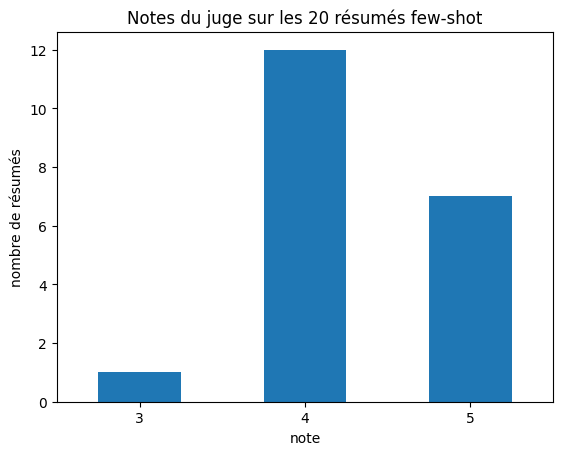

,justification,score
0,Le résumé reprend fidèlement les éléments clés...,5
1,"Le résumé capture fidèlement le dialogue, en i...",4
2,Le résumé capture fidèlement le dialogue : Kat...,4
3,Le résumé conserve fidèlement les éléments clé...,4
4,Le résumé capture correctement les éléments cl...,5
5,"Le résumé capture fidèlement le dialogue, en r...",4
6,Le résumé capture fidèlement le dialogue : Per...,4
7,Le résumé capture fidèlement le contenu du dia...,3
8,Le résumé reproduit fidèlement le contenu du d...,5
9,"Le résumé capture fidèlement le dialogue, en m...",4


In [31]:
class Judgement(BaseModel):
    # La justification est demandée AVANT la note : le modèle « raisonne » avant de conclure.
    justification: str = Field(description="Justification de la note en une ou deux phrases")
    score: int = Field(ge=1, le=5, description="Note de 1 (mauvais) à 5 (excellent)")


JUDGE_PROMPT = """Tu évalues la qualité du résumé d'un dialogue.
Critères : fidélité (aucune information inventée ou fausse) et complétude (les points clés sont présents).

DIALOGUE :
{dialogue}

RÉSUMÉ À ÉVALUER :
{summary}"""


def judge(dialogue, summary):
    """Note de 1 à 5 (fidélité et complétude) d'un résumé, avec justification, par le LLM juge."""
    prompt = JUDGE_PROMPT.format(dialogue=dialogue, summary=summary)
    return generate_structured([{"role": "user", "content": prompt}], Judgement, do_sample=False)


judgements, failures = [], 0
for dialogue, summary in zip(eval_set["dialogue"], few_shot_summaries):
    try:
        judgements.append(judge(dialogue, summary))
    except ValueError:  # un échec ne doit pas interrompre l'évaluation
        failures += 1

print(f"{len(judgements)} résumés notés, {failures} échec(s)")
judge_scores = pd.Series([judgement.score for judgement in judgements])
print(f"Note moyenne : {judge_scores.mean():.2f} / 5")
judge_scores.value_counts().sort_index().plot.bar(
    title="Notes du juge sur les 20 résumés few-shot", xlabel="note", ylabel="nombre de résumés", rot=0
)
plt.show()
pd.DataFrame([judgement.model_dump() for judgement in judgements])

**Question** : peut-on faire confiance à ce juge ? Citez des biais connus des LLM juges. Comment vérifier la fiabilité d'un juge ?

✍️ **Votre réponse :**

Résultat : 20 résumés notés, **aucun échec**, note moyenne **4,30 / 5**, avec uniquement des notes de 3 à 5 (une seule fois 3, 12 fois 4, 7 fois 5). Les justifications se ressemblent toutes (« Le résumé capture fidèlement le dialogue... »).

**On ne peut pas lui faire confiance tel quel.** Ces notes sont élevées alors que ROUGE montre que les résumés few-shot restent éloignés des références (ROUGE-1 ≈ 0,37), et le juge n'utilise presque pas l'échelle.

**Biais connus des LLM juges**
- **Auto-préférence** : ici, le juge est **le même modèle** que celui qui a écrit les résumés ; un modèle tend à préférer ses propres formulations.
- **Indulgence** (*leniency*) : il note généreusement et utilise peu le bas de l'échelle.
- **Biais de longueur** (*verbosity bias*) : il préfère les réponses longues et détaillées.
- **Biais de position** : quand on compare deux réponses, l'ordre de présentation change le verdict.
- **Sensibilité au prompt** : la formulation de la grille et des critères change les notes.
- **Capacité limitée** : un modèle de 1,7 milliard de paramètres peut ne pas repérer une erreur factuelle.

**Comment vérifier la fiabilité d'un juge**
- Faire noter un **échantillon par des humains** et mesurer l'accord avec le juge (corrélation, accord inter-annotateurs).
- **Tests de contrôle** : soumettre des résumés volontairement faux ou incomplets, qui doivent recevoir une mauvaise note.
- Utiliser un juge **différent et plus puissant** que le modèle évalué (voir l'annexe sur les API gratuites).
- Vérifier la **stabilité** : relancer avec d'autres graines ou en permutant l'ordre, et comparer les notes.

### Annexe : utiliser une API gratuite (optionnel)

Pour obtenir un juge plus puissant et **différent** du modèle évalué, vous pouvez utiliser une API offrant un accès gratuit (avec des limites de débit). La plupart sont compatibles avec le client `openai`, ce qui permet de changer de fournisseur en changeant seulement `base_url` et `model` :

| Fournisseur | Inscription | `base_url` |
|---|---|---|
| Google AI Studio (Gemini) | https://aistudio.google.com | `https://generativelanguage.googleapis.com/v1beta/openai/` |
| Groq | https://console.groq.com | `https://api.groq.com/openai/v1` |
| OpenRouter (modèles `:free`) | https://openrouter.ai | `https://openrouter.ai/api/v1` |
| Ollama (local, sur votre machine) | https://ollama.com | `http://localhost:11434/v1` |

Les noms des modèles et les quotas gratuits changent souvent : consultez la documentation du fournisseur (ou `client.models.list()`).

**Règles** :
- ne jamais écrire une clé d'API en clair dans un notebook : utilisez les **Secrets** de Colab (icône 🔑 dans la barre latérale), lus avec `userdata.get(...)` ;
- les offres gratuites peuvent utiliser vos données pour entraîner leurs modèles : n'envoyez **aucune donnée personnelle ou confidentielle**.

In [32]:
# %pip install -q openai
# from google.colab import userdata
# from openai import OpenAI
#
# client = OpenAI(base_url="https://api.groq.com/openai/v1", api_key=userdata.get("GROQ_API_KEY"))
# response = client.chat.completions.create(
#     model="openai/gpt-oss-20b",  # à adapter : voir la liste des modèles du fournisseur
#     messages=[{"role": "user", "content": "Bonjour !"}],
# )
# print(response.choices[0].message.content)

## Bonus : quantification

Les poids d'un modèle sont stockés en float16 (2 octets par paramètre) : un modèle de 8 milliards de paramètres occupe donc environ 16 Go, trop pour le T4. La **quantification** stocke les poids sur moins de bits (8, 4, voire moins) au prix d'une légère perte de qualité. C'est ce qui permet d'exécuter des modèles sur un ordinateur portable (format GGUF avec llama.cpp, Ollama ou LM Studio).

La cellule ci-dessous charge [Qwen3-8B](https://huggingface.co/Qwen/Qwen3-8B) quantifié en 4 bits avec `bitsandbytes`. Elle télécharge 16 Go : exécutez-la seulement si vous avez le temps, après avoir libéré le modèle actuel.

**Question** : comparez la mémoire occupée et la qualité des résumés avec le modèle 1.7B.

In [33]:
# %pip install -q bitsandbytes
# from transformers import BitsAndBytesConfig
#
# del model
# gc.collect()
# torch.cuda.empty_cache()
#
# quantization_config = BitsAndBytesConfig(
#     load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16
# )
# MODEL_NAME = "Qwen/Qwen3-8B"
# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=quantization_config, device_map="auto")
# print(f"Mémoire occupée par le modèle : {model.get_memory_footprint() / 1e9:.1f} Go")

## Mini-projet (au choix)

**Durée estimée** : 3-4 heures. Choisissez **un** des deux sujets. Ils ne demandent que les notions vues dans ce TP.

**Livrables attendus** (pour les deux sujets) :
- code documenté, factorisé (réutilisez `generate`, `generate_structured`...) ;
- une évaluation **quantitative** sur un jeu de test annoté, avec une comparaison de plusieurs approches ;
- une analyse en markdown : ce qui fonctionne, ce qui échoue et pourquoi, pistes d'amélioration.

Pour comparer, vous pouvez utiliser un modèle plus gros qui tient aussi sur le T4, comme [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) (environ 8 Go en float16, sans mode raisonnement). Pensez à libérer la mémoire du modèle précédent (`del model`, `gc.collect()`, `torch.cuda.empty_cache()`) avant de le charger.

### Sujet A : du texte brut à une base de données

Beaucoup de données utiles n'existent que sous forme de texte libre : annonces, comptes rendus, courriels, CV... Un LLM peut les **structurer** pour alimenter une base de données. Mais peut-on faire confiance aux données qu'il produit ?

1. Constituer un corpus d'une vingtaine de textes courts d'un même type (par exemple des annonces immobilières : *« Vends T3 de 68 m² à Poitiers, balcon, 189 000 € »*). Variez les formulations et prévoyez des pièges : informations absentes, plusieurs prix ou surfaces dans le même texte, abréviations (`T3`, `k€`, `CC`), négations (*« sans balcon »*).
2. Définir le schéma cible avec Pydantic (types, `Literal`, champs pouvant valoir `None`) et la table SQLite correspondante, avec des contraintes (`NOT NULL`, `CHECK`).
3. Annoter **à la main** au moins 15 textes : c'est votre vérité terrain.
4. Extraire les données avec `generate_structured`, puis les insérer dans la base avec le module `sqlite3`.
5. Mesurer l'**exactitude champ par champ** par rapport à la vérité terrain, et comparer plusieurs approches : zero-shot, few-shot (exemples d'annonces avec le JSON attendu), mode raisonnement activé, et éventuellement un modèle plus gros.
6. Écrire quelques requêtes SQL d'analyse (prix moyen par type de bien, prix au m²...) et comparer leurs résultats sur les données extraites et sur la vérité terrain.

**Questions** : quels champs sont les plus mal extraits, et pourquoi ? Quelles erreurs du LLM faussent le plus les agrégats ? Que se passe-t-il quand le modèle invente une valeur au lieu de renvoyer `null` ? Quels contrôles ajouteriez-vous avant d'insérer des données produites par un LLM dans une base de production ?

### Sujet B : classification par les probabilités

Pour classer un texte, on peut laisser le LLM **générer** le label, ou bien **lire directement** dans la distribution du token suivant (partie 2) la probabilité de chaque label. La seconde approche donne un score de confiance, et pas seulement une réponse.

Travaillez sur la polarité de critiques de films en français, avec le dataset [allocine](https://huggingface.co/datasets/tblard/allocine) (`load_dataset("tblard/allocine")`, label 0 = négatif, 1 = positif). Utilisez un échantillon **équilibré** d'environ 200 critiques du split `test`, tronquées si elles sont trop longues.

1. **Approche générative** : avec un system prompt adapté, faire générer `positif` ou `négatif`, analyser la réponse et compter les réponses invalides.
2. **Approche par les probabilités** : appliquer le chat template, faire **un seul** passage dans le modèle et comparer la probabilité du premier token de `positif` et de `négatif`. En déduire un score $P(\text{positif}) / (P(\text{positif}) + P(\text{négatif}))$.
3. Évaluer les deux approches : exactitude, matrice de confusion, temps de calcul ; et pour l'approche par les probabilités, l'aire sous la courbe ROC.
4. Étudier l'effet du **nombre d'exemples** few-shot (0, 2, 4, 8 exemples pris dans le split `validation`) et de leur **ordre** (tous les exemples positifs d'abord, ou tous les négatifs d'abord).
5. Étudier le **calibrage** : quand le modèle est sûr à 90 %, a-t-il raison 90 % du temps ? Tracer l'exactitude en fonction de la confiance (*reliability diagram*).

**Questions** : le modèle a-t-il un biais vers l'un des labels ? Le seuil de 0,5 est-il le bon ? Quels avantages pratiques l'approche par les probabilités présente-t-elle (coût, réponses invalides, possibilité de s'abstenir quand le modèle hésite) ? Quelles critiques sont mal classées, et pourquoi (ironie, critiques nuancées...) ?


## Mini-projet : sujet A, du texte brut à une base de données

**Démarche**
1. Un corpus de 20 annonces immobilières courtes, avec des pièges : informations absentes, plusieurs prix ou surfaces dans le même texte, abréviations (`T3`, `F2`, `k€`, `M€`, `CC`, `FAI`), négations (« sans balcon », « pas de balcon »), nombre de chambres donné à la place du nombre de pièces.
2. Un schéma Pydantic (types, `Literal`, champs pouvant valoir `None`) et la table SQLite correspondante, avec des contraintes `NOT NULL` et `CHECK`.
3. Une vérité terrain annotée à la main pour les 20 annonces, validée elle aussi par le schéma.
4. L'extraction avec `generate_structured` selon trois approches : zero-shot, few-shot (3 annonces d'exemple, différentes du corpus de test, avec le JSON attendu) et mode raisonnement.
5. L'exactitude champ par champ, le nombre de valeurs inventées (valeur renvoyée alors que l'information est absente), puis des requêtes SQL d'analyse exécutées sur la vérité terrain et sur les données extraites.

In [34]:
import sqlite3
import unicodedata


class Annonce(BaseModel):
    type_bien: Literal["appartement", "maison", "terrain", "autre"] = Field(
        description="Type de bien : un studio ou un duplex est un appartement, une villa est une maison"
    )
    transaction: Literal["vente", "location"] = Field(description="Bien à vendre ou à louer")
    ville: str | None = Field(description="Nom de la commune seul, sans code postal ni arrondissement ; null si absente")
    surface_m2: float | None = Field(
        description="Surface habitable en m² (pour un terrain : surface du terrain) ; null si absente"
    )
    nb_pieces: int | None = Field(
        description="Nombre de pièces (T3 ou F3 = 3, studio = 1) ; null si non indiqué, "
        "un nombre de chambres n'est pas un nombre de pièces"
    )
    prix_eur: int | None = Field(
        description="Prix de vente ou loyer mensuel en euros tel qu'annoncé, sans ajouter de charges "
        "(189 k€ = 189000) ; s'il y a plusieurs prix, le prix actuellement demandé ; null si absent"
    )
    balcon: bool | None = Field(
        description="true si un balcon est mentionné, false si l'annonce dit qu'il n'y en a pas, null sinon"
    )


# Corpus de test et vérité terrain annotée à la main (une annotation par annonce, dans le même ordre)
CORPUS = [
    ("Vends T3 de 68 m² à Poitiers, balcon, 189 000 €.",
     Annonce(type_bien="appartement", transaction="vente", ville="Poitiers", surface_m2=68, nb_pieces=3, prix_eur=189000, balcon=True)),
    ("Toulon (83000) – Appartement F2 lumineux, 45m2, sans balcon mais proche des plages. Prix : 152 k€.",
     Annonce(type_bien="appartement", transaction="vente", ville="Toulon", surface_m2=45, nb_pieces=2, prix_eur=152000, balcon=False)),
    ("À louer studio meublé 22 m² en centre-ville de Marseille, 650 € CC.",
     Annonce(type_bien="appartement", transaction="location", ville="Marseille", surface_m2=22, nb_pieces=1, prix_eur=650, balcon=None)),
    ("Maison 5 pièces dont 4 chambres, 120 m² habitables sur un terrain de 800 m², La Garde. 459 000 euros.",
     Annonce(type_bien="maison", transaction="vente", ville="La Garde", surface_m2=120, nb_pieces=5, prix_eur=459000, balcon=None)),
    ("Prix baissé ! Appartement T4 à Hyères, 82 m² + balcon de 8 m². Ancien prix 285 000 €, désormais 265 000 €.",
     Annonce(type_bien="appartement", transaction="vente", ville="Hyères", surface_m2=82, nb_pieces=4, prix_eur=265000, balcon=True)),
    ("Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande.",
     Annonce(type_bien="maison", transaction="vente", ville="Avignon", surface_m2=95, nb_pieces=None, prix_eur=None, balcon=None)),
    ("Loue appartement deux pièces, 38 m², Lyon 3e, loyer 780 € hors charges + 60 € de charges.",
     Annonce(type_bien="appartement", transaction="location", ville="Lyon", surface_m2=38, nb_pieces=2, prix_eur=780, balcon=None)),
    ("Terrain constructible de 1 200 m² à Six-Fours-les-Plages, viabilisé, 310 000 €.",
     Annonce(type_bien="terrain", transaction="vente", ville="Six-Fours-les-Plages", surface_m2=1200, nb_pieces=None, prix_eur=310000, balcon=None)),
    ("Bel appartement 3 pièces de 65 m² avec terrasse (pas de balcon), Nice. 1 200 €/mois.",
     Annonce(type_bien="appartement", transaction="location", ville="Nice", surface_m2=65, nb_pieces=3, prix_eur=1200, balcon=False)),
    ("Villa d'architecte, 7 pièces, 210 m², piscine. Saint-Tropez. 2,4 M€.",
     Annonce(type_bien="maison", transaction="vente", ville="Saint-Tropez", surface_m2=210, nb_pieces=7, prix_eur=2400000, balcon=None)),
    ("Vente appart T1 bis 30 m², balcon, quartier de la gare. 98 000 €.",
     Annonce(type_bien="appartement", transaction="vente", ville=None, surface_m2=30, nb_pieces=1, prix_eur=98000, balcon=True)),
    ("Grenoble : T5 de 104 m² au 3e étage avec 2 balcons, 2 places de parking. 249 000 € FAI.",
     Annonce(type_bien="appartement", transaction="vente", ville="Grenoble", surface_m2=104, nb_pieces=5, prix_eur=249000, balcon=True)),
    ("Location maison 4 pièces 90 m² à Bordeaux, jardin de 300 m², 1 450 € charges comprises.",
     Annonce(type_bien="maison", transaction="location", ville="Bordeaux", surface_m2=90, nb_pieces=4, prix_eur=1450, balcon=None)),
    ("Local commercial de 150 m² en rez-de-chaussée, Toulouse centre, à vendre 375 000 €.",
     Annonce(type_bien="autre", transaction="vente", ville="Toulouse", surface_m2=150, nb_pieces=None, prix_eur=375000, balcon=None)),
    ("Studio étudiant à Aix-en-Provence, 18 m², sans balcon, 520 €/mois.",
     Annonce(type_bien="appartement", transaction="location", ville="Aix-en-Provence", surface_m2=18, nb_pieces=1, prix_eur=520, balcon=False)),
    ("Appartement F3 de 70 m² au 3e étage, Montpellier, proposé à 215 000 € (estimation de l'agence : 230 000 €).",
     Annonce(type_bien="appartement", transaction="vente", ville="Montpellier", surface_m2=70, nb_pieces=3, prix_eur=215000, balcon=None)),
    ("Maison à rénover à Draguignan, 4 pièces, environ 100 m², terrain de 2 000 m², 180k€.",
     Annonce(type_bien="maison", transaction="vente", ville="Draguignan", surface_m2=100, nb_pieces=4, prix_eur=180000, balcon=None)),
    ("A louer : T2 45 m² à Paris 11e avec petit balcon. 1 350 € CC.",
     Annonce(type_bien="appartement", transaction="location", ville="Paris", surface_m2=45, nb_pieces=2, prix_eur=1350, balcon=True)),
    ("Appartement familial à Lille, 4 pièces dont 3 chambres, 88 m² Carrez, pas de balcon, 199 000 euros.",
     Annonce(type_bien="appartement", transaction="vente", ville="Lille", surface_m2=88, nb_pieces=4, prix_eur=199000, balcon=False)),
    ("Superbe duplex à vendre à Rennes, balcon filant, 5 pièces. Contactez-nous pour le prix et la surface.",
     Annonce(type_bien="appartement", transaction="vente", ville="Rennes", surface_m2=None, nb_pieces=5, prix_eur=None, balcon=True)),
]
TEXTES = [texte for texte, _ in CORPUS]
VERITE = [annonce for _, annonce in CORPUS]

# Exemples few-shot : annonces différentes du corpus de test, avec le JSON attendu
EXEMPLES = [
    ("Vends T2 de 40 m² à Nantes, sans balcon, 165 000 €.",
     Annonce(type_bien="appartement", transaction="vente", ville="Nantes", surface_m2=40, nb_pieces=2, prix_eur=165000, balcon=False)),
    ("Location maison 3 chambres à Brest, jardin, 950 € CC.",
     Annonce(type_bien="maison", transaction="location", ville="Brest", surface_m2=None, nb_pieces=None, prix_eur=950, balcon=None)),
    ("Appartement 4 pièces avec balcon, Paris 16e, 1,25 M€.",
     Annonce(type_bien="appartement", transaction="vente", ville="Paris", surface_m2=None, nb_pieces=4, prix_eur=1250000, balcon=True)),
]

print(f"{len(CORPUS)} annonces de test annotées, {len(EXEMPLES)} exemples few-shot")
print(describe_schema(Annonce))

20 annonces de test annotées, 3 exemples few-shot
- type_bien (Literal['appartement', 'maison', 'terrain', 'autre']) : Type de bien : un studio ou un duplex est un appartement, une villa est une maison
- transaction (Literal['vente', 'location']) : Bien à vendre ou à louer
- ville (str | None) : Nom de la commune seul, sans code postal ni arrondissement ; null si absente
- surface_m2 (float | None) : Surface habitable en m² (pour un terrain : surface du terrain) ; null si absente
- nb_pieces (int | None) : Nombre de pièces (T3 ou F3 = 3, studio = 1) ; null si non indiqué, un nombre de chambres n'est pas un nombre de pièces
- prix_eur (int | None) : Prix de vente ou loyer mensuel en euros tel qu'annoncé, sans ajouter de charges (189 k€ = 189000) ; s'il y a plusieurs prix, le prix actuellement demandé ; null si absent
- balcon (bool | None) : true si un balcon est mentionné, false si l'annonce dit qu'il n'y en a pas, null sinon


In [35]:
CHAMPS = list(Annonce.model_fields)

connexion = sqlite3.connect("annonces.db")
with connexion:  # transaction : validée si tout réussit, annulée sinon
    connexion.execute("DROP TABLE IF EXISTS annonces")
    connexion.execute("""
        CREATE TABLE annonces (
            source        TEXT    NOT NULL,  -- 'vérité terrain' ou nom de l'approche d'extraction
            id            INTEGER NOT NULL,  -- position de l'annonce dans le corpus
            type_bien     TEXT    NOT NULL CHECK (type_bien IN ('appartement', 'maison', 'terrain', 'autre')),
            "transaction" TEXT    NOT NULL CHECK ("transaction" IN ('vente', 'location')),
            ville         TEXT,
            surface_m2    REAL    CHECK (surface_m2 > 0),
            nb_pieces     INTEGER CHECK (nb_pieces > 0),
            prix_eur      INTEGER CHECK (prix_eur > 0),
            balcon        INTEGER CHECK (balcon IN (0, 1)),
            PRIMARY KEY (source, id)
        )
    """)

INSERT = (
    'INSERT INTO annonces (source, id, type_bien, "transaction", ville, surface_m2, nb_pieces, prix_eur, balcon) '
    "VALUES (:source, :id, :type_bien, :transaction, :ville, :surface_m2, :nb_pieces, :prix_eur, :balcon)"
)


def inserer(source, annonces):
    """Insère les annonces d'une source (None = extraction échouée) ; renvoie le nombre de lignes rejetées par la base."""
    with connexion:  # les lignes d'une exécution précédente sont remplacées : la cellule peut être relancée
        connexion.execute("DELETE FROM annonces WHERE source = ?", (source,))
    rejets = 0
    for id_annonce, annonce in enumerate(annonces):
        if annonce is None:
            continue
        try:
            with connexion:
                connexion.execute(INSERT, {"source": source, "id": id_annonce, **annonce.model_dump()})
        except sqlite3.IntegrityError:  # une contrainte CHECK ou NOT NULL n'est pas respectée
            rejets += 1
    return rejets


print("Lignes de vérité terrain rejetées :", inserer("vérité terrain", VERITE))
pd.read_sql_query("SELECT * FROM annonces", connexion)

Lignes de vérité terrain rejetées : 0


,source,id,type_bien,transaction,ville,surface_m2,nb_pieces,prix_eur,balcon
0,vérité terrain,0,appartement,vente,Poitiers,68.0,3.0,189000.0,1.0
1,vérité terrain,1,appartement,vente,Toulon,45.0,2.0,152000.0,0.0
2,vérité terrain,2,appartement,location,Marseille,22.0,1.0,650.0,NaN
3,vérité terrain,3,maison,vente,La Garde,120.0,5.0,459000.0,NaN
4,vérité terrain,4,appartement,vente,Hyères,82.0,4.0,265000.0,1.0
5,vérité terrain,5,maison,vente,Avignon,95.0,NaN,NaN,NaN
6,vérité terrain,6,appartement,location,Lyon,38.0,2.0,780.0,NaN
7,vérité terrain,7,terrain,vente,Six-Fours-les-Plages,1200.0,NaN,310000.0,NaN
8,vérité terrain,8,appartement,location,Nice,65.0,3.0,1200.0,0.0
9,vérité terrain,9,maison,vente,Saint-Tropez,210.0,7.0,2400000.0,NaN


In [40]:
SYSTEM_EXTRACTION = (
    "Tu extrais les informations d'annonces immobilières. "
    "N'invente rien : une information absente de l'annonce vaut null."
)


def extraction_messages(texte, exemples=()):
    """Messages d'extraction : system prompt, puis un tour (annonce, JSON attendu) par exemple, puis l'annonce."""
    messages = [{"role": "system", "content": SYSTEM_EXTRACTION}]
    for exemple, attendu in exemples:
        messages += [
            {"role": "user", "content": f"Annonce : {exemple}"},  # même format que l'annonce à traiter
            {"role": "assistant", "content": attendu.model_dump_json()},
        ]
    messages.append({"role": "user", "content": f"Annonce : {texte}"})
    return messages


def extraire(texte, exemples=(), **gen_kwargs):
    """Annonce extraite par le LLM, ou None si aucune réponse valide n'a été obtenue."""
    try:
        return generate_structured(extraction_messages(texte, exemples), Annonce, **gen_kwargs)
    except ValueError:
        return None


APPROCHES = {
    "zero-shot": dict(exemples=(), do_sample=False),
    "few-shot": dict(exemples=EXEMPLES, do_sample=False),
    # paramètres recommandés par Qwen pour le mode raisonnement (voir partie 4.3)
    "raisonnement": dict(
        exemples=(), enable_thinking=True, max_new_tokens=2048, do_sample=True, temperature=0.6, top_p=0.95, top_k=20
    ),
}

predictions, durees = {}, {}
for nom, parametres in APPROCHES.items():
    set_seed(0)
    start = time.perf_counter()
    predictions[nom] = [extraire(texte, **parametres) for texte in TEXTES]
    durees[nom] = time.perf_counter() - start
    print(f"{nom:13s}: {durees[nom]:5.0f} s, {predictions[nom].count(None)} extraction(s) échouée(s)")

zero-shot    :    68 s, 0 extraction(s) échouée(s)
few-shot     :    48 s, 0 extraction(s) échouée(s)
raisonnement :   374 s, 0 extraction(s) échouée(s)


,zero-shot,few-shot,raisonnement
type_bien,100%,95%,100%
transaction,100%,100%,100%
ville,95%,90%,100%
surface_m2,100%,100%,100%
nb_pieces,80%,75%,90%
prix_eur,85%,95%,100%
balcon,75%,45%,100%


,exactitude moyenne,annonces entièrement correctes,valeurs inventées,extractions échouées,lignes rejetées par SQLite,durée (s)
zero-shot,0.907,9,6,0,0,68
few-shot,0.857,4,11,0,0,48
raisonnement,0.986,18,1,0,0,374


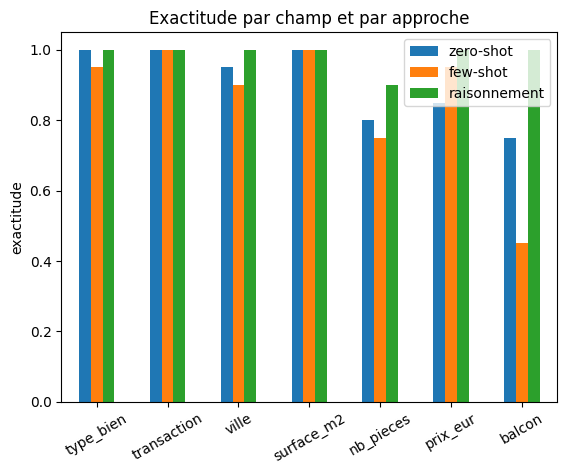

In [41]:
def normaliser(valeur):
    """Rend comparables deux valeurs : casse, accents et tirets ignorés pour le texte, surfaces arrondies au m²."""
    if isinstance(valeur, str):
        sans_accents = unicodedata.normalize("NFKD", valeur).encode("ascii", "ignore").decode()
        return re.sub(r"[\s-]+", " ", sans_accents).strip().casefold()
    if isinstance(valeur, float):
        return round(valeur)
    return valeur


def champ_correct(annonce, verite, champ):
    """Le champ extrait est-il égal à la vérité terrain ? (une extraction échouée est fausse)"""
    return annonce is not None and normaliser(getattr(annonce, champ)) == normaliser(getattr(verite, champ))


def exactitude_par_champ(annonces):
    """Proportion d'annonces dont chaque champ est correctement extrait."""
    return {
        champ: sum(champ_correct(annonce, verite, champ) for annonce, verite in zip(annonces, VERITE)) / len(VERITE)
        for champ in CHAMPS
    }


def nb_inventions(annonces):
    """Nombre de valeurs renvoyées alors que l'information est absente de l'annonce (null attendu)."""
    return sum(
        annonce is not None and getattr(verite, champ) is None and getattr(annonce, champ) is not None
        for annonce, verite in zip(annonces, VERITE)
        for champ in CHAMPS
    )


rejets = {nom: inserer(nom, annonces) for nom, annonces in predictions.items()}

exactitudes = pd.DataFrame({nom: exactitude_par_champ(annonces) for nom, annonces in predictions.items()})
display(exactitudes.style.format("{:.0%}"))

synthese = pd.DataFrame.from_dict(orient="index", data={  # une ligne par approche
    nom: {
        "exactitude moyenne": round(exactitudes[nom].mean(), 3),
        "annonces entièrement correctes": sum(
            all(champ_correct(annonce, verite, champ) for champ in CHAMPS) for annonce, verite in zip(annonces, VERITE)
        ),
        "valeurs inventées": nb_inventions(annonces),
        "extractions échouées": annonces.count(None),
        "lignes rejetées par SQLite": rejets[nom],
        "durée (s)": round(durees[nom]),
    }
    for nom, annonces in predictions.items()
})
display(synthese)

exactitudes.plot.bar(title="Exactitude par champ et par approche", ylabel="exactitude", rot=30, ylim=(0, 1.05))
plt.show()

In [42]:
def erreurs(nom):
    """Détail des champs mal extraits par une approche."""
    lignes = []
    for id_annonce, (annonce, verite) in enumerate(zip(predictions[nom], VERITE)):
        for champ in CHAMPS:
            if not champ_correct(annonce, verite, champ):
                lignes.append({
                    "annonce": id_annonce,
                    "champ": champ,
                    "attendu": getattr(verite, champ),
                    "obtenu": None if annonce is None else getattr(annonce, champ),
                    "texte": TEXTES[id_annonce],
                })
    return pd.DataFrame(lignes)


with pd.option_context("display.max_colwidth", 120, "display.max_rows", 200):
    for nom in predictions:
        print(f"{dash_line}\nErreurs de l'approche {nom}")
        display(erreurs(nom))

----------------------------------------------------------------------------------------------------
Erreurs de l'approche zero-shot


,annonce,champ,attendu,obtenu,texte
0,1,nb_pieces,2,3,"Toulon (83000) – Appartement F2 lumineux, 45m2, sans balcon mais proche des plages. Prix : 152 k€."
1,4,nb_pieces,4,3,"Prix baissé ! Appartement T4 à Hyères, 82 m² + balcon de 8 m². Ancien prix 285 000 €, désormais 265 000 €."
2,5,nb_pieces,None,3,"Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande."
3,5,prix_eur,None,189000,"Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande."
4,5,balcon,None,True,"Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande."
5,8,balcon,False,None,"Bel appartement 3 pièces de 65 m² avec terrasse (pas de balcon), Nice. 1 200 €/mois."
6,9,balcon,None,True,"Villa d'architecte, 7 pièces, 210 m², piscine. Saint-Tropez. 2,4 M€."
7,10,ville,None,la gare,"Vente appart T1 bis 30 m², balcon, quartier de la gare. 98 000 €."
8,11,nb_pieces,5,2,"Grenoble : T5 de 104 m² au 3e étage avec 2 balcons, 2 places de parking. 249 000 € FAI."
9,14,balcon,False,None,"Studio étudiant à Aix-en-Provence, 18 m², sans balcon, 520 €/mois."


----------------------------------------------------------------------------------------------------
Erreurs de l'approche few-shot


,annonce,champ,attendu,obtenu,texte
0,1,nb_pieces,2,4,"Toulon (83000) – Appartement F2 lumineux, 45m2, sans balcon mais proche des plages. Prix : 152 k€."
1,1,balcon,False,None,"Toulon (83000) – Appartement F2 lumineux, 45m2, sans balcon mais proche des plages. Prix : 152 k€."
2,2,nb_pieces,1,2,"À louer studio meublé 22 m² en centre-ville de Marseille, 650 € CC."
3,2,balcon,None,True,"À louer studio meublé 22 m² en centre-ville de Marseille, 650 € CC."
4,3,balcon,None,True,"Maison 5 pièces dont 4 chambres, 120 m² habitables sur un terrain de 800 m², La Garde. 459 000 euros."
5,5,nb_pieces,None,3,"Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande."
6,5,balcon,None,True,"Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande."
7,6,balcon,None,True,"Loue appartement deux pièces, 38 m², Lyon 3e, loyer 780 € hors charges + 60 € de charges."
8,8,balcon,False,True,"Bel appartement 3 pièces de 65 m² avec terrasse (pas de balcon), Nice. 1 200 €/mois."
9,9,type_bien,maison,autre,"Villa d'architecte, 7 pièces, 210 m², piscine. Saint-Tropez. 2,4 M€."


----------------------------------------------------------------------------------------------------
Erreurs de l'approche raisonnement


,annonce,champ,attendu,obtenu,texte
0,5,nb_pieces,NaN,3.0,"Particulier vend maison de ville à Avignon, 3 chambres, jardin, 95 m². Prix sur demande."
1,11,nb_pieces,5.0,NaN,"Grenoble : T5 de 104 m² au 3e étage avec 2 balcons, 2 places de parking. 249 000 € FAI."


In [43]:
REQUETES = {
    "Prix de vente moyen par type de bien": """
        SELECT type_bien, source, ROUND(AVG(prix_eur)) AS valeur
        FROM annonces
        WHERE "transaction" = 'vente'
        GROUP BY type_bien, source
    """,
    "Prix moyen au m² des appartements à vendre": """
        SELECT 'appartement' AS type_bien, source, ROUND(AVG(prix_eur / surface_m2)) AS valeur
        FROM annonces
        WHERE "transaction" = 'vente' AND type_bien = 'appartement' AND prix_eur IS NOT NULL AND surface_m2 IS NOT NULL
        GROUP BY source
    """,
    "Loyer mensuel moyen par type de bien": """
        SELECT type_bien, source, ROUND(AVG(prix_eur)) AS valeur
        FROM annonces
        WHERE "transaction" = 'location'
        GROUP BY type_bien, source
    """,
    "Nombre d'annonces avec balcon": """
        SELECT 'tous' AS type_bien, source, SUM(balcon) AS valeur
        FROM annonces
        GROUP BY source
    """,
}

for titre, requete in REQUETES.items():
    print(titre)
    display(pd.read_sql_query(requete, connexion).pivot(index="type_bien", columns="source", values="valeur"))

Prix de vente moyen par type de bien


source,few-shot,raisonnement,vérité terrain,zero-shot
type_bien,,,,
appartement,327125.0,195286.0,195286.0,194500.0
autre,1387500.0,375000.0,375000.0,375000.0
maison,319500.0,1013000.0,1013000.0,809250.0
terrain,310000.0,310000.0,310000.0,310000.0


Prix moyen au m² des appartements à vendre


source,few-shot,raisonnement,vérité terrain,zero-shot
type_bien,,,,
appartement,2912.0,2912.0,2912.0,2912.0


Loyer mensuel moyen par type de bien


source,few-shot,raisonnement,vérité terrain,zero-shot
type_bien,,,,
appartement,900.0,900.0,900.0,900.0
maison,1450.0,1450.0,1450.0,1450.0


Nombre d'annonces avec balcon


source,few-shot,raisonnement,vérité terrain,zero-shot
type_bien,,,,
tous,15,6,6,8


### Analyse

**Résultats** (20 annonces, 7 champs par annonce)
| approche | exactitude moyenne | annonces entièrement correctes | valeurs inventées | durée |
|---|---|---|---|---|
| zero-shot | 90,7 % | 9 / 20 | 6 | 68 s |
| few-shot (3 exemples) | 85,7 % | 4 / 20 | 11 | 48 s |
| **raisonnement** | **98,6 %** | **18 / 20** | **1** | 374 s |

Aucune extraction n'a échoué (le JSON a toujours fini par être valide) et aucune ligne n'a été rejetée par les contraintes SQLite.

**Quels champs sont les plus mal extraits, et pourquoi ?**
- **`balcon`** (75 % en zero-shot, 45 % en few-shot) : le modèle confond « absent de l'annonce » (`null`) et « explicitement absent » (`false`). Les négations « sans balcon » et « pas de balcon » donnent souvent `null`, et à l'inverse il invente `true` pour des maisons ou une villa qui ne parlent pas de balcon.
- **`nb_pieces`** (80 % et 75 %) : les abréviations sont mal décodées (F2 → 3, T4 → 3, T5 → 2), et « 3 chambres » est converti en 3 pièces alors que l'annonce ne donne pas le nombre de pièces. Même le mode raisonnement fait ces deux erreurs (T5 non reconnu, chambres comptées comme pièces).
- **`prix_eur`** (85 % en zero-shot) : des prix sont **inventés** pour des annonces qui n'en ont pas, ou recopiés. La valeur 189 000 apparaît trois fois en zero-shot (Avignon, Rennes, et Draguignan au lieu de 180 000) : c'est l'exemple donné dans la **description du champ** (« 189 k€ = 189000 »). Le modèle recopie une valeur du prompt au lieu de lire l'annonce.
- **Le few-shot fait moins bien que le zero-shot** : le modèle imite les exemples au lieu de s'en inspirer. Il met un balcon presque partout, et il donne au duplex de Rennes (sans prix) le prix de l'exemple « Appartement 4 pièces avec balcon, 1,25 M€ », c'est-à-dire 1 250 000 €. J'ai vérifié que ce n'était pas un problème de format : les exemples sont présentés exactement comme l'annonce à traiter. Avec un petit modèle, des exemples peu variés créent un biais vers leurs valeurs.

**Quelles erreurs faussent le plus les agrégats ?** Les **prix inventés** et les **erreurs de type de bien** :
- few-shot : prix moyen des appartements à vendre de **327 125 €** au lieu de 195 286 € (le 1 250 000 € inventé pour Rennes), et prix moyen des biens « autre » de **1 387 500 €** au lieu de 375 000 € (la villa à 2,4 M€ classée « autre » au lieu de « maison ») ;
- zero-shot : prix moyen des maisons de **809 250 €** au lieu de 1 013 000 € (le prix de 189 000 € inventé pour Avignon) ;
- nombre d'annonces avec balcon : **15** en few-shot et 8 en zero-shot, pour 6 en réalité.

Le prix moyen au m² est resté juste, mais par chance : les prix inventés concernent des annonces sans surface, exclues par le filtre `surface_m2 IS NOT NULL`. Une seule valeur extrême suffit à déplacer fortement une moyenne sur un petit échantillon.

**Que se passe-t-il quand le modèle invente une valeur au lieu de renvoyer `null` ?** L'erreur devient **silencieuse** : la valeur a le bon type et est plausible, donc elle passe la validation Pydantic **et** les contraintes `CHECK` de SQLite (aucune ligne rejetée). Elle est stockée comme un fait, impossible à distinguer d'une vraie donnée, et elle entre dans les calculs. Un `null` est préférable : la fonction `AVG` l'ignore et il signale honnêtement l'information manquante. C'est l'hallucination du cours, appliquée à une base de données.

**Quels contrôles ajouter avant d'insérer des données produites par un LLM dans une base de production ?**
- **Vérifier l'ancrage dans le texte** : chaque valeur numérique (prix, surface, pièces) doit pouvoir être retrouvée dans l'annonce, par exemple par une expression régulière ; sinon, mettre `null` ou envoyer en revue.
- **Validateurs métier** dans Pydantic et en SQL : plages plausibles (un loyer reste inférieur à quelques milliers d'euros, une vente dépasse quelques dizaines de milliers d'euros, prix au m² dans une fourchette réaliste), cohérence entre champs (un terrain n'a pas de nombre de pièces).
- **Ne pas mettre de valeurs concrètes dans les consignes et les exemples**, puisque le modèle les recopie, et choisir des exemples variés (avec des `null` et des `false`).
- **Table intermédiaire et revue humaine** des lignes suspectes, plutôt qu'une insertion directe.
- **Double extraction** (deux approches ou deux modèles) : insérer seulement si les résultats concordent, sinon faire vérifier.
- **Traçabilité** : enregistrer le modèle, la version du prompt et le texte source avec chaque ligne.
- **Décodage contraint** (outlines, xgrammar), qui garantit le format, mais pas la vérité des valeurs.

**Bilan** : le mode raisonnement est nettement le plus fiable (18 annonces sur 20 entièrement correctes, une seule valeur inventée), mais il est 5,5 fois plus lent que le zero-shot. Limites de cette évaluation : 20 annonces seulement, une seule exécution (le mode raisonnement est échantillonné, donc ses résultats varient d'une exécution à l'autre), et des annonces et annotations écrites par la même personne. Pistes d'amélioration : un modèle plus gros (Qwen3-4B-Instruct-2507), des descriptions de champs sans valeur d'exemple, des exemples few-shot plus variés ou choisis par similarité avec l'annonce, et les contrôles ci-dessus.